  [binary] confound=0.2 done (5s)
  [binary] confound=0.4 done (10s)
  [binary] confound=0.6 done (15s)
  [binary] confound=0.8 done (19s)
  [binary] effect=0.8 done (24s)
  [binary] effect=1.5 done (29s)
  [binary] effect=2.2 done (33s)
  [binary] effect=3.0 done (38s)
  [continuous] confound=0.2 done (42s)
  [continuous] confound=0.4 done (46s)
  [continuous] confound=0.6 done (50s)
  [continuous] confound=0.8 done (54s)
  [continuous] effect=0.8 done (58s)
  [continuous] effect=1.5 done (62s)
  [continuous] effect=2.2 done (66s)
  [continuous] effect=3.0 done (70s)

================ SUMMARY ================

--- BINARY latent ---
interaction AUC      : {'GWAS': [0.94, 0.95, 0.91, 0.93], 'IBI-DT': [0.73, 0.68, 0.64, 0.59], 'Pathway': [0.94, 0.95, 0.93, 0.93]}
interaction Type I   : {'GWAS': [0.0, 0.03, 0.2, 0.09], 'IBI-DT': [0.03, 0.08, 0.12, 0.08], 'Pathway': [0.03, 0.08, 0.11, 0.09]}
DRIVER Type I        : {'GWAS': [0.11, 0.56, 0.81, 1.0], 'IBI-DT': [0.14, 0.39, 0.41, 0.48], 'Pathw

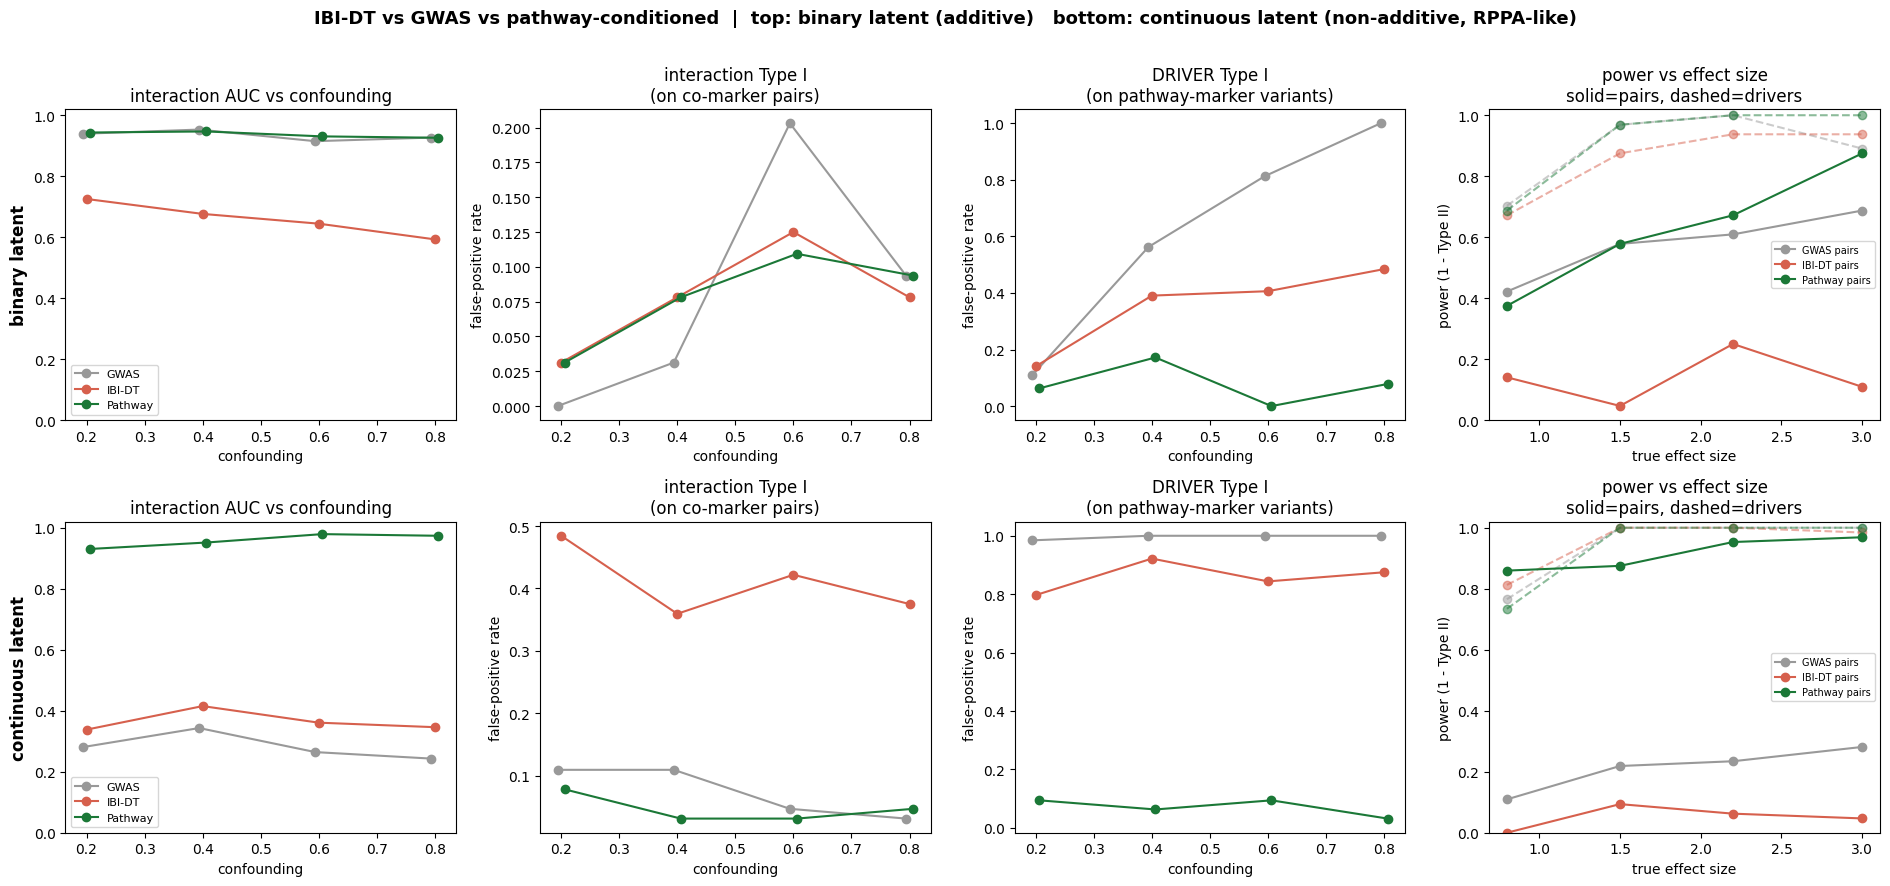

In [ ]:
"""
Error-rate study v2: drivers AND interactions, binary vs continuous latent
==========================================================================
Same generator family as before (hidden pathway -> marker genes -> outcome T),
now with two additions you asked for:

  1) DRIVER Type I / Type II, not just interactions. Single-variant detection
     is the alpha side of IBI-DT, and it is exactly where additive confounding
     inflates marginal tests -- so it is where conditioning on the pathway helps
     most. We report driver false-positive rate on null variants and power.

  2) A CONTINUOUS-LATENT variant. Biologically: a pathway is not an on/off
     switch but an ACTIVITY LEVEL, and its read-outs are continuous protein /
     expression measurements (think RPPA). Mathematically this is the regime
     where the shared latent leaks a spurious PRODUCT term into the outcome
     (phantom epistasis for interactions), so conditioning on the inferred
     latent should pull clearly ahead of a plain product-term (GWAS) test.

       binary latent     : Z in {0,1}, markers Bernoulli(theta_z)   -> additive
       continuous latent : Z ~ N(0,1), markers G = lambda*Z + noise -> NOT additive

Three method arms throughout:
   GWAS     : one-at-a-time. Marginal logistic per variant (drivers);
              logistic with a product term per pair (interactions).
   IBI-DT   : faithful tree ensemble -> alpha (drivers), beta (interactions),
              with the random-node null as the significance threshold.
   Pathway  : infer the latent pathway state from its markers (Gibbs latent
              class for binary; Gaussian factor model for continuous), then
              test each variant / pair AFTER conditioning on it; calibrated.

Method lineage (NOT invented here): latent-confounder adjustment = SVA / PEER /
RUV; Bayesian null/main/interaction partition = BEAM; the failure mode = phantom
epistasis. Contribution here is the diagnosis + pathway-anchored assembly.

Self-contained: numpy / scipy / sklearn / matplotlib.
"""

import numpy as np
from scipy.special import gammaln, expit, logsumexp
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
import time

# ============================================================================
# shared marginal-likelihood / evidence pieces
# ============================================================================
def lgm_edge(T, Vmat):
    T = T.astype(np.int64); Vmat = Vmat.astype(np.int64)
    t1, t0 = T, 1 - T
    V1D1 = t1 @ Vmat; V1D0 = t0 @ Vmat
    V0D1 = t1 @ (1 - Vmat); V0D0 = t0 @ (1 - Vmat)
    lg = np.zeros(Vmat.shape[1])
    for a, b in [(V0D0, V0D1), (V1D0, V1D1)]:
        lg += gammaln(2.0) - gammaln(2.0 + a + b) + gammaln(1.0 + a) + gammaln(1.0 + b)
    return lg

def lgm_noparent(T):
    N = len(T); N1 = int(T.sum())
    return gammaln(2.0) - gammaln(2.0 + N) + gammaln(1.0 + N - N1) + gammaln(1.0 + N1)

def logistic_logevidence(X, y, tau=4.0, iters=40):
    d = X.shape[1]; b = np.zeros(d); P = np.eye(d) / tau**2
    for _ in range(iters):
        mu = expit(X @ b); W = mu * (1 - mu) + 1e-9
        H = X.T @ (X * W[:, None]) + P
        step = np.linalg.solve(H, X.T @ (y - mu) - P @ b); b += step
        if np.max(np.abs(step)) < 1e-7:
            break
    eta = X @ b; mu = expit(eta); W = mu * (1 - mu) + 1e-9
    ll = np.sum(y * eta - np.logaddexp(0.0, eta))
    _, logdetH = np.linalg.slogdet(X.T @ (X * W[:, None]) + P)
    return ll - 0.5 * (b @ b) / tau**2 - 0.5*d*np.log(tau**2) - 0.5 * logdetH

def logistic_wald_p(X, y, idx, iters=40):
    from math import erfc, sqrt
    d = X.shape[1]; b = np.zeros(d)
    for _ in range(iters):
        mu = expit(X @ b); W = mu * (1 - mu) + 1e-9
        H = X.T @ (X * W[:, None]) + 1e-6 * np.eye(d)
        step = np.linalg.solve(H, X.T @ (y - mu)); b += step
        if np.max(np.abs(step)) < 1e-7:
            break
    mu = expit(X @ b); W = mu * (1 - mu) + 1e-9
    cov = np.linalg.inv(X.T @ (X * W[:, None]) + 1e-9 * np.eye(d))
    z = b[idx] / np.sqrt(max(cov[idx, idx], 1e-12))
    return erfc(abs(z) / sqrt(2))

# ============================================================================
# STEP 1 -- infer the latent, TWO versions
# ============================================================================
def infer_Z_binary(G_block, n_draws=12, iters=500, burn=200, seed=0):
    """Gibbs latent-class model for BINARY markers -> posterior draws of Z in {0,1}."""
    rng = np.random.default_rng(seed); n, m = G_block.shape
    Z = (rng.random(n) < 0.5).astype(int); draws = []; thin = max((iters - burn)//n_draws, 1)
    for it in range(iters):
        th = np.empty((m, 2))
        for z in (0, 1):
            on = G_block[Z == z].sum(0)
            th[:, z] = rng.beta(1 + on, 1 + ((Z == z).sum() - on))
        pi = rng.beta(1 + Z.sum(), 1 + (n - Z.sum()))
        if th[:, 1].sum() < th[:, 0].sum():
            th, pi, Z = th[:, ::-1], 1 - pi, 1 - Z
        lo = (np.log(pi/(1-pi)) + G_block @ np.log(th[:, 1]/th[:, 0])
              + (1 - G_block) @ np.log((1-th[:, 1])/(1-th[:, 0])))
        Z = (rng.random(n) < expit(lo)).astype(int)
        if it >= burn and (it-burn) % thin == 0 and len(draws) < n_draws:
            draws.append(Z.astype(float).copy())
    return np.array(draws)

def infer_Z_continuous(G_block, n_draws=12, iters=400, burn=150, seed=0):
    """One-factor Gaussian factor model for CONTINUOUS markers (RPPA-style):
       G_j = lambda_j * Z + noise.  Gibbs -> posterior draws of the factor Z (real)."""
    rng = np.random.default_rng(seed); n, m = G_block.shape
    G = (G_block - G_block.mean(0)) / (G_block.std(0) + 1e-9)
    lam = np.ones(m); psi = np.ones(m); Z = rng.standard_normal(n)
    draws = []; thin = max((iters - burn)//n_draws, 1)
    for it in range(iters):
        # Z_i | . ~ N(mu_i, v)   (posterior of the factor score)
        v = 1.0 / (1.0 + np.sum(lam**2 / psi))
        mu = v * (G @ (lam / psi))
        Z = mu + np.sqrt(v) * rng.standard_normal(n)
        # lambda_j | . ~ N(.,.)   (regress each marker on Z)
        zz = Z @ Z + 1e-6
        for j in range(m):
            mlam = (G[:, j] @ Z) / zz; vlam = psi[j] / zz
            lam[j] = mlam + np.sqrt(vlam) * rng.standard_normal()
        # psi_j | . ~ InvGamma  (residual variance)
        resid = G - np.outer(Z, lam)
        psi = (np.sum(resid**2, 0) + 1.0) / rng.chisquare(n + 2, size=m)
        if lam.sum() < 0:                    # fix sign (identifiability)
            lam, Z = -lam, -Z
        if it >= burn and (it-burn) % thin == 0 and len(draws) < n_draws:
            draws.append(Z.copy())
    return np.array(draws)                   # real-valued factor scores

# ============================================================================
# IBI-DT faithful tree + ensemble (binary inputs; for continuous markers we
# binarise at the median so IBI-DT still has something to split on, as a user
# would have to do in practice)
# ============================================================================
def grow(T, V, idx, cand, depth, max_depth, neglogq, min_n, used, path, paths):
    Tn = T[idx]
    if depth >= max_depth or len(idx) < min_n or Tn.min() == Tn.max():
        paths.append(list(path)); return
    usable = [c for c in cand if c not in used and V[idx, c].min() != V[idx, c].max()]
    if not usable:
        paths.append(list(path)); return
    gains = lgm_edge(Tn, V[np.ix_(idx, usable)]) - lgm_noparent(Tn)
    j = int(np.argmax(gains))
    if gains[j] <= neglogq:
        paths.append(list(path)); return
    s = usable[j]
    for branch in (0, 1):
        child = idx[V[idx, s] == branch]
        if len(child):
            grow(T, V, child, cand, depth+1, max_depth, neglogq, min_n,
                 used | {s}, path + [(s, branch)], paths)

def ibidt_alpha_beta(T, Vbin, N=30, max_depth=4, q=0.1, min_n=25, rng=None):
    rng = rng or np.random.default_rng(0)
    p = Vbin.shape[1]; cand = list(range(p)); neglogq = -np.log(q)
    alpha = np.zeros(p); beta = {}; i1, i0 = np.where(T == 1)[0], np.where(T == 0)[0]
    a_null = b_null = 0
    for _ in range(N):
        bs = np.concatenate([rng.choice(i0, len(i0), True), rng.choice(i1, len(i1), True)])
        paths = []
        grow(T[bs], Vbin[bs], np.arange(len(bs)), cand, 0, max_depth, neglogq, min_n, set(), [], paths)
        nodes = {v for pth in paths for v, _ in pth}
        for s in nodes: alpha[s] += 1
        seen = set()
        for pth in paths:
            vs = [v for v, _ in pth]
            for x in range(len(vs)):
                for y in range(x+1, len(vs)):
                    k = (min(vs[x], vs[y]), max(vs[x], vs[y]))
                    if k not in seen: beta[k] = beta.get(k, 0)+1; seen.add(k)
        ac, bc, bs2 = {}, {}, set()
        for pth in paths:
            rl = [int(rng.integers(p)) for _ in pth]
            for v in set(rl): ac[v] = ac.get(v, 0)+1
            for x in range(len(rl)):
                for y in range(x+1, len(rl)):
                    k = (min(rl[x], rl[y]), max(rl[x], rl[y]))
                    if k not in bs2: bc[k] = bc.get(k, 0)+1; bs2.add(k)
        a_null = max(a_null, max(ac.values()) if ac else 0)
        b_null = max(b_null, max(bc.values()) if bc else 0)
    return alpha, beta, a_null, b_null

# ============================================================================
# GENERATOR -- one function, switchable latent type
# ============================================================================
def make_data(effect_size=2.0, confound_strength=0.55, n=700, p_extra_nulls=12,
              n_pathways=2, per=5, n_drivers=4, n_inter=4, latent="binary", seed=0):
    rng = np.random.default_rng(seed)
    blocks, Zs = [], []
    for _ in range(n_pathways):
        if latent == "binary":
            Z = (rng.random(n) < 0.45).astype(float)
            theta1, theta0 = 0.5 + confound_strength/2, 0.5 - confound_strength/2
            B = np.zeros((n, per))
            for j in range(per):
                B[:, j] = (rng.random(n) < np.where(Z == 1, theta1, theta0)).astype(float)
        else:  # continuous: pathway ACTIVITY level; markers are noisy linear read-outs (RPPA-like)
            Z = rng.standard_normal(n)
            lam = 0.5 + confound_strength            # loading grows with confounding
            noise = np.sqrt(max(1.0 - 0.0, 0.3))
            B = lam * Z[:, None] + noise * rng.standard_normal((n, per))
        Zs.append(Z); blocks.append(B)

    D = (rng.random((n, n_drivers)) < 0.30).astype(float)        # true single-variant drivers
    E = (rng.random((n, 2*n_inter)) < 0.5).astype(float)         # true interaction genes
    NU = (rng.random((n, p_extra_nulls)) < 0.25).astype(float)   # nulls
    V = np.hstack(blocks + [D, E, NU])

    off = {}; c = 0
    for k in range(n_pathways): off[f"path{k}"] = c; c += per
    off["drv"] = c; c += n_drivers
    off["int"] = c; c += 2*n_inter
    off["null"] = c

    logit = -2.0
    for Z in Zs:
        logit = logit + (2.2 * Z if latent == "binary" else 1.6 * Z)   # pathway acts additively
    for d in range(n_drivers):
        logit = logit + effect_size * D[:, d]
    for q in range(n_inter):
        a, b = off["int"]+2*q, off["int"]+2*q+1
        logit = logit + effect_size * ((V[:, a] > 0.5) & (V[:, b] > 0.5)).astype(float)
    T = (rng.random(n) < expit(logit)).astype(int)

    # binarised copy of the SGA matrix for IBI-DT and as the 0/1 'genotype' for GWAS/pathway
    Vbin = (V > np.median(V, 0)).astype(float) if latent == "continuous" else V.copy()
    # for marker columns keep the binary draws when binary; for continuous, median-split
    marker_cols = list(range(n_pathways*per))

    true_drivers = set(range(off["drv"], off["drv"]+n_drivers))
    true_pairs = {(off["int"]+2*q, off["int"]+2*q+1) for q in range(n_inter)}
    marker_pick = [off["path0"]+0, off["path0"]+1] + \
                  ([off["path1"]+0, off["path1"]+1] if n_pathways > 1 else [])
    driver_cands = [(g, "pos") for g in range(off["drv"], off["drv"]+n_drivers)] + \
                   [(g, "null") for g in range(off["null"], off["null"]+min(6, p_extra_nulls))] + \
                   [(g, "phantom") for g in marker_pick]   # correlate with T via pathway only
    pair_cands = [(pr, "pos") for pr in true_pairs]
    for k in range(n_pathways):
        b0 = off[f"path{k}"]
        pair_cands += [((b0+0, b0+1), "phantom"), ((b0+2, b0+3), "phantom")]
    nb = off["null"]
    pair_cands += [((nb+0, nb+1), "null"), ((nb+2, nb+3), "null"), ((nb+4, nb+5), "null")]
    return dict(V=V, Vbin=Vbin, T=T, off=off, per=per, n_pathways=n_pathways, latent=latent,
                true_drivers=true_drivers, true_pairs=true_pairs,
                driver_cands=driver_cands, pair_cands=pair_cands, marker_cols=marker_cols)

# ============================================================================
# score one dataset with all three methods (drivers + pairs)
# ============================================================================
def score_dataset(dat, rng):
    V, Vbin, T = dat["V"], dat["Vbin"], dat["T"]; n = len(T); one = np.ones(n)
    alpha, beta, a_null, b_null = ibidt_alpha_beta(T, Vbin, rng=rng)
    infer = infer_Z_binary if dat["latent"] == "binary" else infer_Z_continuous
    Zd = [infer(dat["V"][:, dat["off"][f"path{k}"]:dat["off"][f"path{k}"]+dat["per"]],
                seed=int(rng.integers(1e9))) for k in range(dat["n_pathways"])]
    S = min(len(z) for z in Zd)
    Zlist = [np.column_stack([Zd[k][s] for k in range(dat["n_pathways"])]) for s in range(S)]

    # ---- drivers: returns rows (label, gwas, ibidt, pcond) + kind
    drv_rows, drv_kind = [], []
    for g, kind in dat["driver_cands"]:
        lab = int(kind == "pos"); Gg = Vbin[:, g].astype(float)
        gwas = -np.log(max(logistic_wald_p(np.column_stack([one, Gg]), T, 1), 1e-300))
        ibidt = alpha[g] - a_null
        ev0, ev1 = [], []
        for Z in Zlist:
            base = np.column_stack([one] + [Z[:, k] for k in range(Z.shape[1])])
            ev0.append(logistic_logevidence(base, T))
            ev1.append(logistic_logevidence(np.column_stack([base, Gg]), T))
        drv_rows.append((lab, gwas, ibidt, logsumexp(ev1)-logsumexp(ev0))); drv_kind.append(kind)

    # ---- pairs
    pair_rows, pair_kind = [], []
    for (a, b), kind in dat["pair_cands"]:
        lab = int(kind == "pos")
        Ga, Gb = Vbin[:, a].astype(float), Vbin[:, b].astype(float); inter = Ga*Gb
        gwas = -np.log(max(logistic_wald_p(np.column_stack([one, Ga, Gb, inter]), T, 3), 1e-300))
        ibidt = beta.get((min(a, b), max(a, b)), 0) - b_null
        ev_add, ev_int = [], []
        for Z in Zlist:
            base = np.column_stack([one] + [Z[:, k] for k in range(Z.shape[1])] + [Ga, Gb])
            ev_add.append(logistic_logevidence(base, T))
            ev_int.append(logistic_logevidence(np.column_stack([base, inter]), T))
        pair_rows.append((lab, gwas, ibidt, logsumexp(ev_int)-logsumexp(ev_add))); pair_kind.append(kind)
    return drv_rows, drv_kind, pair_rows, pair_kind

# ============================================================================
# run both latent types over the sweeps
# ============================================================================
def auc(L, S): return roc_auc_score(L, S) if len(set(L)) == 2 else np.nan
NATIVE = {"GWAS": -np.log(0.05), "IBI-DT": 0.5, "Pathway": np.log(3.0)}
methods = ["GWAS", "IBI-DT", "Pathway"]
R = 16
conf_grid = [0.2, 0.4, 0.6, 0.8]
t0 = time.time()

def run_latent(latent):
    # sweep confounding: interaction AUC, phantom Type I (pairs), driver Type I (null variants)
    pair_auc = {m: [] for m in methods}; pair_phantomI = {m: [] for m in methods}
    drv_typeI = {m: [] for m in methods}; drv_auc = {m: [] for m in methods}
    for cs in conf_grid:
        PL, Pk = {m: [] for m in methods}, []
        DL, Dk = {m: [] for m in methods}, []
        plab, dlab = [], []
        for r in range(R):
            dat = make_data(effect_size=2.0, confound_strength=cs, n=700, latent=latent,
                            seed=1000*r + int(cs*10))
            dr, dk, pr, pk = score_dataset(dat, np.random.default_rng(50000+r))
            dr = np.array(dr, float); pr = np.array(pr, float)
            dlab += list(dr[:, 0]); plab += list(pr[:, 0]); Dk += dk; Pk += pk
            for i, m in enumerate(methods):
                DL[m] += list(dr[:, i+1]); PL[m] += list(pr[:, i+1])
        plab, dlab = np.array(plab), np.array(dlab); Pk, Dk = np.array(Pk), np.array(Dk)
        for m in methods:
            sP, sD = np.array(PL[m]), np.array(DL[m])
            pair_auc[m].append(auc(plab, sP)); drv_auc[m].append(auc(dlab, sD))
            pair_phantomI[m].append(float(np.mean(sP[Pk == "phantom"] >= NATIVE[m])))
            drv_typeI[m].append(float(np.mean(sD[Dk == "phantom"] >= NATIVE[m])))
        print(f"  [{latent}] confound={cs} done ({time.time()-t0:.0f}s)")

    # sweep effect size: interaction power and driver power
    eff_grid = [0.8, 1.5, 2.2, 3.0]
    pair_pow = {m: [] for m in methods}; drv_pow = {m: [] for m in methods}
    for es in eff_grid:
        PL, DL, plab, dlab, Pk, Dk = {m: [] for m in methods}, {m: [] for m in methods}, [], [], [], []
        for r in range(R):
            dat = make_data(effect_size=es, confound_strength=0.55, n=700, latent=latent,
                            seed=2000*r + int(es*10))
            dr, dk, pr, pk = score_dataset(dat, np.random.default_rng(60000+r))
            dr = np.array(dr, float); pr = np.array(pr, float)
            dlab += list(dr[:, 0]); plab += list(pr[:, 0]); Dk += dk; Pk += pk
            for i, m in enumerate(methods):
                DL[m] += list(dr[:, i+1]); PL[m] += list(pr[:, i+1])
        plab, dlab = np.array(plab), np.array(dlab)
        for m in methods:
            sP, sD = np.array(PL[m]), np.array(DL[m])
            pair_pow[m].append(float(np.mean(sP[plab == 1] >= NATIVE[m])))
            drv_pow[m].append(float(np.mean(sD[dlab == 1] >= NATIVE[m])))
        print(f"  [{latent}] effect={es} done ({time.time()-t0:.0f}s)")
    return dict(conf=conf_grid, eff=eff_grid, pair_auc=pair_auc, pair_phantomI=pair_phantomI,
                drv_typeI=drv_typeI, drv_auc=drv_auc, pair_pow=pair_pow, drv_pow=drv_pow)

res = {"binary": run_latent("binary"), "continuous": run_latent("continuous")}

# ============================================================================
# figure : rows = {binary, continuous}, cols = 4 panels
# ============================================================================
col = {"GWAS": "#999999", "IBI-DT": "#d6604d", "Pathway": "#1b7837"}
jit = {"GWAS": -0.006, "IBI-DT": 0.0, "Pathway": 0.006}
fig, AX = plt.subplots(2, 4, figsize=(19, 9))
for row, latent in enumerate(["binary", "continuous"]):
    r = res[latent]; ax = AX[row]
    # 1: interaction AUC vs confounding
    for m in methods: ax[0].plot(np.array(r["conf"])+jit[m], r["pair_auc"][m], "o-", color=col[m], label=m)
    ax[0].set_ylim(0.0, 1.02); ax[0].set_ylabel(f"{latent} latent", fontsize=12, fontweight="bold")
    ax[0].set_title("interaction AUC vs confounding"); ax[0].set_xlabel("confounding"); ax[0].legend(fontsize=8)
    # 2: phantom Type I (pairs) vs confounding
    for m in methods: ax[1].plot(np.array(r["conf"])+jit[m], r["pair_phantomI"][m], "o-", color=col[m])
    ax[1].set_title("interaction Type I\n(on co-marker pairs)"); ax[1].set_xlabel("confounding")
    ax[1].set_ylabel("false-positive rate")
    # 3: DRIVER Type I vs confounding  (the newly added panel)
    for m in methods: ax[2].plot(np.array(r["conf"])+jit[m], r["drv_typeI"][m], "o-", color=col[m])
    ax[2].set_title("DRIVER Type I\n(on pathway-marker variants)"); ax[2].set_xlabel("confounding")
    ax[2].set_ylabel("false-positive rate")
    # 4: power vs effect size (pairs solid, drivers dashed)
    for m in methods:
        ax[3].plot(r["eff"], r["pair_pow"][m], "o-", color=col[m], label=f"{m} pairs")
        ax[3].plot(r["eff"], r["drv_pow"][m], "o--", color=col[m], alpha=.5)
    ax[3].set_ylim(0, 1.02); ax[3].set_title("power vs effect size\nsolid=pairs, dashed=drivers")
    ax[3].set_xlabel("true effect size"); ax[3].set_ylabel("power (1 - Type II)"); ax[3].legend(fontsize=7)
fig.suptitle("IBI-DT vs GWAS vs pathway-conditioned  |  top: binary latent (additive)   bottom: continuous latent (non-additive, RPPA-like)",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig("error_rate_study_v2.png", dpi=135)

print("\n================ SUMMARY ================")
for latent in ["binary", "continuous"]:
    r = res[latent]
    print(f"\n--- {latent.upper()} latent ---")
    print("interaction AUC      :", {m: [round(x, 2) for x in r["pair_auc"][m]] for m in methods})
    print("interaction Type I   :", {m: [round(x, 2) for x in r["pair_phantomI"][m]] for m in methods})
    print("DRIVER Type I        :", {m: [round(x, 2) for x in r["drv_typeI"][m]] for m in methods})
    print("interaction power    :", {m: [round(x, 2) for x in r["pair_pow"][m]] for m in methods})
    print("driver power         :", {m: [round(x, 2) for x in r["drv_pow"][m]] for m in methods})
print("saved figure -> error_rate_study_v2.png")

  10/30 cohorts done
  20/30 cohorts done
  30/30 cohorts done

================ SUMMARY ================
pooled pairs: 90 true, 90 phantom, 90 null;  base rate pi0=0.33
AUC vs experiment   pathway=0.99  naive=0.99
calibration ECE (pathway prob, true base rate): 0.042
mean log BF   true=+7.70  phantom=-2.00  null=-1.86
saved figure -> perturbation_validation.png


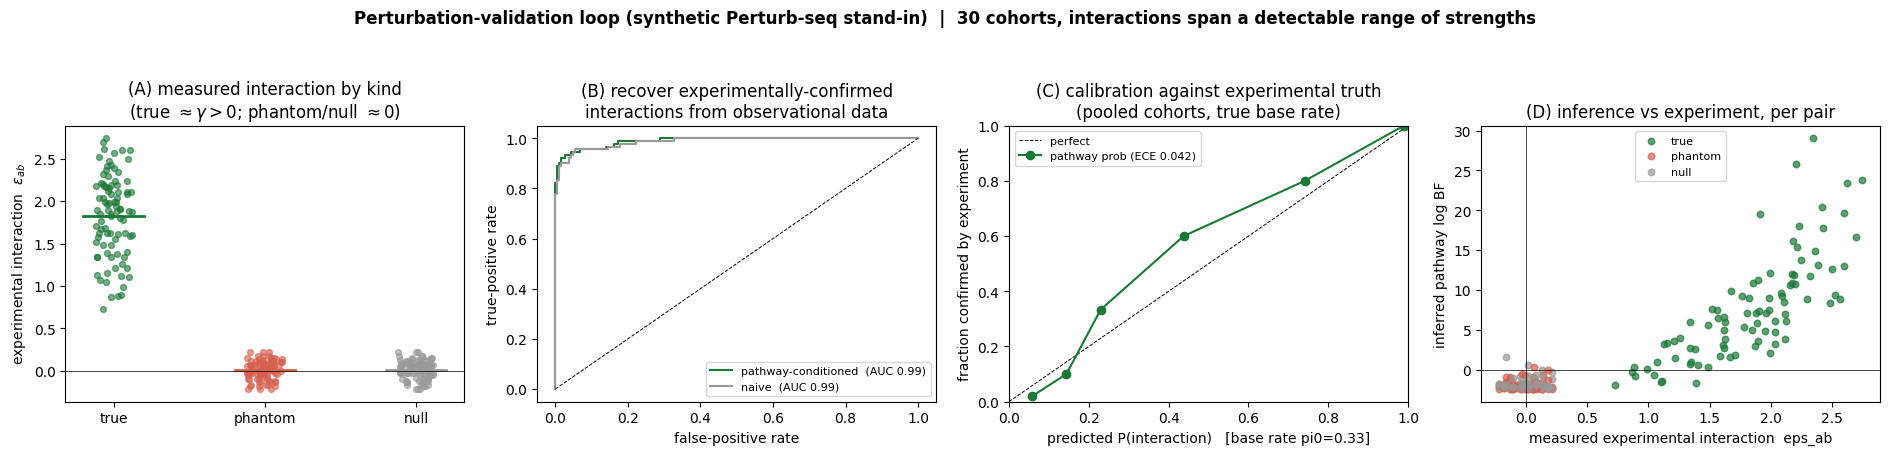

In [ ]:
"""
Perturbation-validation prototype  (SYNTHETIC stand-in for Perturb-seq)
======================================================================
Validation loop: define interaction by INTERVENTION, infer it from OBSERVATION,
check one against the other.

  1) Perturb-seq-style experiment (control / KO a / KO b / KO both) -> the
     experimental interaction is the 2x2 contrast
         eps_ab = phi(both KO) - phi(KO a) - phi(KO b) + phi(control).
  2) OBSERVATIONAL cohorts (pathway confounding + planted interactions) -> infer
     P(interaction) per pair, blind to the knockouts (naive vs pathway-conditioned).
  3) VALIDATE: ROC + calibration of the inferred probability against experiment.

DESIGN NOTE (why many small cohorts).  A single binary outcome can only host a
FEW real interactions before their combined effect saturates it and nothing is
detectable.  So, exactly as in a proper calibration study, we generate MANY
cohorts, each with a handful of interactions at a RANDOM strength, and pool the
results.  Probabilities are formed with the TRUE base rate pi0 of the candidate
set (not a placeholder 0.5), so the reliability diagram is honest.

ON REAL DATA: replace `perturbseq_eps` with a loader for a combinatorial
Perturb-seq set and compute eps_ab from its single/double cells the same way.
Self-contained: numpy / scipy / sklearn / matplotlib.
"""

import numpy as np
from scipy.special import expit, logsumexp
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# ---------------- inference pieces ----------------
def logistic_logevidence(X, y, tau=4.0, iters=40):
    d = X.shape[1]; b = np.zeros(d); P = np.eye(d)/tau**2
    for _ in range(iters):
        mu = expit(X@b); W = mu*(1-mu)+1e-9
        H = X.T@(X*W[:, None]) + P
        step = np.linalg.solve(H, X.T@(y-mu) - P@b); b += step
        if np.max(np.abs(step)) < 1e-7: break
    eta = X@b; mu = expit(eta); W = mu*(1-mu)+1e-9
    ll = np.sum(y*eta - np.logaddexp(0.0, eta))
    _, logdetH = np.linalg.slogdet(X.T@(X*W[:, None]) + P)
    return ll - 0.5*(b@b)/tau**2 - 0.5*d*np.log(tau**2) - 0.5*logdetH

def infer_Z_binary(G_block, n_draws=8, iters=300, burn=100, seed=0):
    rng = np.random.default_rng(seed); n, m = G_block.shape
    Z = (rng.random(n) < 0.5).astype(int); draws = []; thin = max((iters-burn)//n_draws, 1)
    for it in range(iters):
        th = np.empty((m, 2))
        for z in (0, 1):
            on = G_block[Z == z].sum(0); th[:, z] = rng.beta(1+on, 1+((Z == z).sum()-on))
        pi = rng.beta(1+Z.sum(), 1+(n-Z.sum()))
        if th[:, 1].sum() < th[:, 0].sum(): th, pi, Z = th[:, ::-1], 1-pi, 1-Z
        lo = (np.log(pi/(1-pi)) + G_block@np.log(th[:, 1]/th[:, 0])
              + (1-G_block)@np.log((1-th[:, 1])/(1-th[:, 0])))
        Z = (rng.random(n) < expit(lo)).astype(int)
        if it >= burn and (it-burn) % thin == 0 and len(draws) < n_draws:
            draws.append(Z.astype(float).copy())
    return np.array(draws)

def interaction_logBF(Ga, Gb, T, Zlist=None):
    one = np.ones(len(T)); inter = (Ga*Gb).astype(float)
    if Zlist is None:
        base = np.column_stack([one, Ga, Gb])
        return logistic_logevidence(np.column_stack([base, inter]), T) - logistic_logevidence(base, T)
    ev_add, ev_int = [], []
    for Z in Zlist:
        base = np.column_stack([one] + [Z[:, k] for k in range(Z.shape[1])] + [Ga, Gb])
        ev_add.append(logistic_logevidence(base, T))
        ev_int.append(logistic_logevidence(np.column_stack([base, inter]), T))
    return (logsumexp(ev_int)-np.log(len(ev_int))) - (logsumexp(ev_add)-np.log(len(ev_add)))

# ---------------- experimental side: eps from a 2x2 perturbation contrast ----------------
def perturbseq_eps(gamma, n_cells=400, seed=0):
    rng = np.random.default_rng(seed)
    a_eff, b_eff = rng.normal(0.8, 0.3), rng.normal(0.8, 0.3)
    def phi(xa, xb): return 2.0 + a_eff*xa + b_eff*xb + gamma*xa*xb
    m = {(xa, xb): (phi(xa, xb)+rng.normal(0, 1.0, n_cells)).mean()
         for (xa, xb) in [(1, 1), (0, 1), (1, 0), (0, 0)]}
    eps = m[(0, 0)] - m[(0, 1)] - m[(1, 0)] + m[(1, 1)]
    return eps, m

# ---------------- one observational cohort: a FEW interactions, not saturating ----------------
N_TRUE_DS, N_PHANTOM_DS, N_NULL_DS = 3, 3, 3     # per cohort
N_PATH, PER = 2, 8
BASE_RATE = N_TRUE_DS / (N_TRUE_DS + N_PHANTOM_DS + N_NULL_DS)   # 1/3

def one_cohort(seed, n=800, confound=0.55):
    rng = np.random.default_rng(seed)
    theta1, theta0 = 0.5+confound/2, 0.5-confound/2
    Zs, blocks = [], []
    for _ in range(N_PATH):
        Z = (rng.random(n) < 0.45).astype(float); Zs.append(Z)
        B = np.array([(rng.random(n) < np.where(Z == 1, theta1, theta0)).astype(float)
                      for _ in range(PER)]).T
        blocks.append(B)
    Pm = np.hstack(blocks)
    gammas = rng.uniform(0.9, 2.6, N_TRUE_DS)             # a few real interactions, varied strength
    Et = (rng.random((n, 2*N_TRUE_DS)) < 0.5).astype(float)
    NU = (rng.random((n, 2*N_NULL_DS)) < 0.30).astype(float)
    logit = -2.0
    for Z in Zs: logit = logit + 2.2*Z
    for k in range(N_TRUE_DS):
        logit = logit + gammas[k]*((Et[:, 2*k] > .5) & (Et[:, 2*k+1] > .5)).astype(float)
    T = (rng.random(n) < expit(logit)).astype(int)
    # candidate pairs
    cand = []   # (kind, gamma, Ga, Gb)
    for k in range(N_TRUE_DS):
        cand.append(("true", gammas[k], Et[:, 2*k], Et[:, 2*k+1]))
    pp = [(0, 0, 1), (0, 2, 3), (1, 0, 1)][:N_PHANTOM_DS]      # co-marker pairs within pathways
    for (pth, j1, j2) in pp:
        cand.append(("phantom", 0.0, Pm[:, pth*PER+j1], Pm[:, pth*PER+j2]))
    for k in range(N_NULL_DS):
        cand.append(("null", 0.0, NU[:, 2*k], NU[:, 2*k+1]))
    # infer Z per pathway
    Zd = [infer_Z_binary(Pm[:, p*PER:(p+1)*PER], seed=seed+1+p) for p in range(N_PATH)]
    S = min(len(z) for z in Zd)
    Zlist = [np.column_stack([Zd[p][s] for p in range(N_PATH)]) for s in range(S)]
    out = []
    for (kind, g, Ga, Gb) in cand:
        naive = interaction_logBF(Ga, Gb, T, Zlist=None)
        cond = interaction_logBF(Ga, Gb, T, Zlist=Zlist)
        eps, _ = perturbseq_eps(g, seed=seed+999+int(1000*g))
        out.append((kind, g, eps, naive, cond, int(g > 0)))
    return out

R = 30
recs = []
for r in range(R):
    recs += one_cohort(seed=1000*r)
    if (r+1) % 10 == 0: print(f"  {r+1}/{R} cohorts done")

kind = np.array([x[0] for x in recs]); gam = np.array([x[1] for x in recs])
eps = np.array([x[2] for x in recs]); naive = np.array([x[3] for x in recs])
cond = np.array([x[4] for x in recs]); lab = np.array([x[5] for x in recs])

def to_prob(lbf, pi0): bf = np.exp(np.clip(lbf, -30, 30)); return pi0*bf/(pi0*bf+(1-pi0))
P_cond = to_prob(cond, BASE_RATE)

def ece(pred, y, nb=10):
    edges = np.linspace(0, 1, nb+1); e = 0.0
    for i in range(nb):
        m = (pred >= edges[i]) & ((pred <= edges[i+1]) if i == nb-1 else (pred < edges[i+1]))
        if m.sum() > 0: e += m.sum()/len(pred)*abs(y[m].mean()-pred[m].mean())
    return e

# ---------------- figure ----------------
fig, ax = plt.subplots(1, 4, figsize=(19, 4.6))

# (A) experimental interaction eps by pair kind (uses all pooled pairs)
for xi, (k, color) in enumerate([("true", "#1b7837"), ("phantom", "#d6604d"), ("null", "#999999")]):
    e = eps[kind == k]
    ax[0].scatter(np.full(e.shape, xi) + np.random.uniform(-.12, .12, e.shape), e,
                  color=color, s=18, alpha=.6)
    ax[0].plot([xi-.2, xi+.2], [e.mean(), e.mean()], color=color, lw=2)  # mean bar
ax[0].axhline(0, color="k", lw=.5)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(["true", "phantom", "null"])
ax[0].set_ylabel("experimental interaction  $\\varepsilon_{ab}$")
ax[0].set_title("(A) measured interaction by kind\n(true $\\approx\\gamma>0$; phantom/null $\\approx 0$)")

# (B) ROC vs experimental label
for sc, color, name in [(cond, "#1b7837", "pathway-conditioned"), (naive, "#999999", "naive")]:
    fpr, tpr, _ = roc_curve(lab, sc)
    ax[1].plot(fpr, tpr, color=color, label=f"{name}  (AUC {roc_auc_score(lab, sc):.2f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=.7)
ax[1].set_xlabel("false-positive rate"); ax[1].set_ylabel("true-positive rate")
ax[1].set_title("(B) recover experimentally-confirmed\ninteractions from observational data")
ax[1].legend(fontsize=8, loc="lower right")

# (C) calibration with true base rate
nb = 10; edges = np.linspace(0, 1, nb+1); conf, acc = [], []
for i in range(nb):
    m = (P_cond >= edges[i]) & ((P_cond <= edges[i+1]) if i == nb-1 else (P_cond < edges[i+1]))
    if m.sum() >= 5: conf.append(P_cond[m].mean()); acc.append(lab[m].mean())
ax[2].plot([0, 1], [0, 1], "k--", lw=.7, label="perfect")
ax[2].plot(conf, acc, "o-", color="#1b7837", label=f"pathway prob (ECE {ece(P_cond, lab):.3f})")
ax[2].set_xlabel(f"predicted P(interaction)   [base rate pi0={BASE_RATE:.2f}]")
ax[2].set_ylabel("fraction confirmed by experiment")
ax[2].set_title("(C) calibration against experimental truth\n(pooled cohorts, true base rate)")
ax[2].set_xlim(0, 1); ax[2].set_ylim(0, 1); ax[2].legend(fontsize=8)

# (D) inferred score vs measured experimental interaction
cmap = {"true": "#1b7837", "phantom": "#d6604d", "null": "#999999"}
shown = set()
for i in range(len(recs)):
    lb = kind[i] if kind[i] not in shown else None; shown.add(kind[i])
    ax[3].scatter(eps[i], cond[i], color=cmap[kind[i]], s=22, alpha=.7, label=lb)
ax[3].axhline(0, color="k", lw=.5); ax[3].axvline(0, color="k", lw=.5)
ax[3].set_xlabel("measured experimental interaction  eps_ab")
ax[3].set_ylabel("inferred pathway log BF")
ax[3].set_title("(D) inference vs experiment, per pair")
ax[3].legend(fontsize=8)

fig.suptitle("Perturbation-validation loop (synthetic Perturb-seq stand-in)  |  "
             f"{R} cohorts, interactions span a detectable range of strengths",
             fontsize=12, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig("perturbation_validation.png", dpi=135)

print("\n================ SUMMARY ================")
print(f"pooled pairs: {(kind=='true').sum()} true, {(kind=='phantom').sum()} phantom, "
      f"{(kind=='null').sum()} null;  base rate pi0={BASE_RATE:.2f}")
print(f"AUC vs experiment   pathway={roc_auc_score(lab, cond):.2f}  naive={roc_auc_score(lab, naive):.2f}")
print(f"calibration ECE (pathway prob, true base rate): {ece(P_cond, lab):.3f}")
print(f"mean log BF   true={cond[kind=='true'].mean():+.2f}  "
      f"phantom={cond[kind=='phantom'].mean():+.2f}  null={cond[kind=='null'].mean():+.2f}")
print("saved figure -> perturbation_validation.png")

Running Panel A family (driver + interaction, Gibbs conditioning)...
  [binary] c=0.20  DRIVER FPR  Unco=0.21  True=0.00  Gibb=0.03  Gibb=0.13   (3s)
  [binary] c=0.40  DRIVER FPR  Unco=0.94  True=0.00  Gibb=0.00  Gibb=0.18   (7s)
  [binary] c=0.60  DRIVER FPR  Unco=1.00  True=0.00  Gibb=0.00  Gibb=0.02   (11s)
  [binary] c=0.80  DRIVER FPR  Unco=1.00  True=0.00  Gibb=0.01  Gibb=0.01   (17s)
  [continuous] c=0.20  DRIVER FPR  Unco=1.00  True=0.01  Gibb=0.00  Gibb=0.03   (4s)
  [continuous] c=0.40  DRIVER FPR  Unco=1.00  True=0.01  Gibb=0.00  Gibb=0.01   (8s)
  [continuous] c=0.60  DRIVER FPR  Unco=1.00  True=0.01  Gibb=0.01  Gibb=0.01   (12s)
  [continuous] c=0.80  DRIVER FPR  Unco=1.00  True=0.01  Gibb=0.01  Gibb=0.01   (16s)
saved figure -> panel_a_family_conditioning.png

===== FPR at log BF > log 3 =====

--- binary latent / driver ---
  Unconditioned        [0.206, 0.938, 1.0, 1.0]
  True Z               [0.0, 0.0, 0.0, 0.0]
  Gibbs (point est.)   [0.031, 0.0, 0.0, 0.006]
  Gibbs 

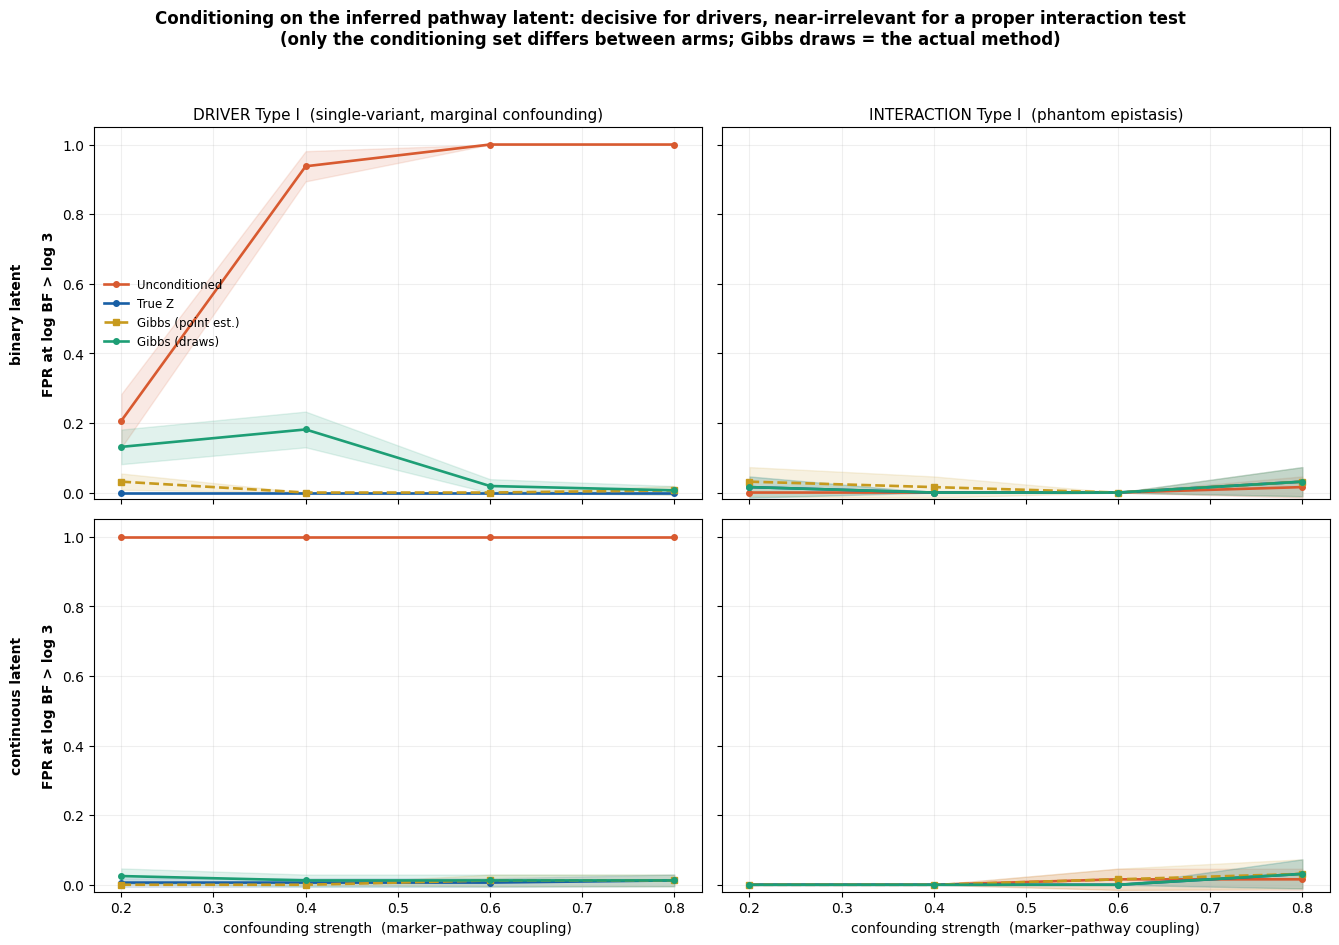

In [3]:
"""
Panel A family, rebuilt and corrected -- where conditioning on an inferred
pathway latent actually matters, and where it does not.

Earlier I demonstrated "interaction Type I vs confounding" and attributed a
residual to the inference step. Diagnostics with the proper machinery showed
that was wrong on two counts:

  * A correctly specified interaction Bayes factor (tested BEYOND main effects,
    with a prior penalty) already controls additive-latent confounding on
    co-marker pairs. Conditioning on Z then has little left to fix, so the
    "interaction Type I vs confounding" curve is essentially a NULL. Phantom
    epistasis, as diagnosed, is a beta / co-occurrence artifact -- a property of
    the statistic IBI-DT uses, not of a well-specified test.

  * Where conditioning is decisive is the DRIVER (single-variant) side: a marker
    looks like a strong driver purely because it proxies the pathway that drives
    the outcome. That marginal confounding is severe and additive, and
    conditioning on the latent removes it.

This script therefore reports BOTH, as four conditioning arms of ONE evidence
statistic (the only thing that changes between arms is the conditioning set):

  Unconditioned     : test the feature beyond [1, (G_a, G_b for pairs)]
  True Z            : ... beyond [1, Z_true, ...]                  (oracle ceiling)
  Gibbs (point est) : ... beyond [1, Zbar, ...]                    (posterior MEAN)
  Gibbs (draws)     : log-mean-exp of the evidence over Z draws    (the actual method)

Run in both the BINARY-latent (additive) and CONTINUOUS-latent (RPPA-like)
regimes. The honest headline: conditioning -- and integrating over the
posterior, not a point estimate -- rescues DRIVER calls; the interaction test is
robust either way. Step 1 = the user's Gibbs samplers; Step 2 = the user's
Laplace log-evidence integrated over draws.

Self-contained: numpy / scipy / matplotlib.
"""

import numpy as np
from scipy.special import expit, logsumexp
import matplotlib.pyplot as plt
import time

LOG_BF_THRESHOLD = np.log(3.0)   # Jeffreys' "substantial"; the call rule


# ============================================================================
# Step 2 -- Laplace log-evidence + integration over draws  (user's machinery)
# ============================================================================
def logistic_logevidence(X, y, tau=4.0, iters=60):
    n, d = X.shape
    beta = np.zeros(d); Pi = np.eye(d) / tau**2
    for _ in range(iters):
        mu = expit(X @ beta); W = mu * (1 - mu) + 1e-9
        g = X.T @ (y - mu) - Pi @ beta
        H = X.T @ (X * W[:, None]) + Pi
        step = np.linalg.solve(H, g); beta += step
        if np.max(np.abs(step)) < 1e-8:
            break
    eta = X @ beta
    ll = np.sum(y * eta - np.logaddexp(0.0, eta))
    mu = expit(eta); W = mu * (1 - mu) + 1e-9
    H = X.T @ (X * W[:, None]) + Pi
    _, logdetH = np.linalg.slogdet(H)
    logprior = -0.5 * d * np.log(tau**2) - 0.5 * (beta @ beta) / tau**2
    return ll + logprior - 0.5 * logdetH


def logmeanexp(a):
    a = np.asarray(a, float)
    return logsumexp(a) - np.log(len(a))


def _cond_cols(one, Z):
    cols = [one]
    if Z is not None and np.size(Z):
        Z = np.asarray(Z, float)
        if Z.ndim == 1:
            Z = Z[:, None]
        cols.extend(Z[:, k] for k in range(Z.shape[1]))
    return cols


def driver_logBF(G, T, cond_list, tau=4.0):
    """log BF for the main effect of G beyond [1, (conditioners)]."""
    one = np.ones(len(T)); G = G.astype(float)
    ev0, ev1 = [], []
    for Z in cond_list:
        base = _cond_cols(one, Z)
        ev0.append(logistic_logevidence(np.column_stack(base), T, tau))
        ev1.append(logistic_logevidence(np.column_stack(base + [G]), T, tau))
    return logmeanexp(ev1) - logmeanexp(ev0)


def interaction_logBF(Ga, Gb, T, cond_list, tau=4.0):
    """log BF for the Ga:Gb term beyond [1, (conditioners), Ga, Gb]."""
    one = np.ones(len(T)); inter = (Ga * Gb).astype(float)
    ev_add, ev_int = [], []
    for Z in cond_list:
        base = _cond_cols(one, Z) + [Ga.astype(float), Gb.astype(float)]
        ev_add.append(logistic_logevidence(np.column_stack(base), T, tau))
        ev_int.append(logistic_logevidence(np.column_stack(base + [inter]), T, tau))
    return logmeanexp(ev_int) - logmeanexp(ev_add)


# ============================================================================
# Step 1 -- the user's Gibbs samplers (verbatim), two latent types
# ============================================================================
def infer_Z_binary(G_block, n_draws=12, iters=500, burn=200, seed=0):
    rng = np.random.default_rng(seed); n, m = G_block.shape
    Z = (rng.random(n) < 0.5).astype(int); draws = []
    thin = max((iters - burn) // n_draws, 1)
    for it in range(iters):
        th = np.empty((m, 2))
        for z in (0, 1):
            on = G_block[Z == z].sum(0)
            th[:, z] = rng.beta(1 + on, 1 + ((Z == z).sum() - on))
        pi = rng.beta(1 + Z.sum(), 1 + (n - Z.sum()))
        if th[:, 1].sum() < th[:, 0].sum():
            th, pi, Z = th[:, ::-1], 1 - pi, 1 - Z
        lo = (np.log(pi / (1 - pi)) + G_block @ np.log(th[:, 1] / th[:, 0])
              + (1 - G_block) @ np.log((1 - th[:, 1]) / (1 - th[:, 0])))
        Z = (rng.random(n) < expit(lo)).astype(int)
        if it >= burn and (it - burn) % thin == 0 and len(draws) < n_draws:
            draws.append(Z.astype(float).copy())
    return np.array(draws)


def infer_Z_continuous(G_block, n_draws=12, iters=400, burn=150, seed=0):
    rng = np.random.default_rng(seed); n, m = G_block.shape
    G = (G_block - G_block.mean(0)) / (G_block.std(0) + 1e-9)
    lam = np.ones(m); psi = np.ones(m); Z = rng.standard_normal(n)
    draws = []; thin = max((iters - burn) // n_draws, 1)
    for it in range(iters):
        v = 1.0 / (1.0 + np.sum(lam**2 / psi))
        mu = v * (G @ (lam / psi))
        Z = mu + np.sqrt(v) * rng.standard_normal(n)
        zz = Z @ Z + 1e-6
        for j in range(m):
            mlam = (G[:, j] @ Z) / zz; vlam = psi[j] / zz
            lam[j] = mlam + np.sqrt(vlam) * rng.standard_normal()
        resid = G - np.outer(Z, lam)
        psi = (np.sum(resid**2, 0) + 1.0) / rng.chisquare(n + 2, size=m)
        if lam.sum() < 0:
            lam, Z = -lam, -Z
        if it >= burn and (it - burn) % thin == 0 and len(draws) < n_draws:
            draws.append(Z.copy())
    return np.array(draws)


# ============================================================================
# Generator -- v2 family, NULL world (no planted drivers or interactions)
# ============================================================================
def make_data(confound_strength=0.55, n=600, n_pathways=2, per=5,
              n_null_genes=12, latent="binary", gamma=None, seed=0):
    rng = np.random.default_rng(seed)
    if gamma is None:
        gamma = 2.2 if latent == "binary" else 1.6
    blocks, Zs = [], []
    for _ in range(n_pathways):
        if latent == "binary":
            Z = (rng.random(n) < 0.45).astype(float)
            theta1, theta0 = 0.5 + confound_strength / 2, 0.5 - confound_strength / 2
            B = np.zeros((n, per))
            for j in range(per):
                B[:, j] = (rng.random(n) < np.where(Z == 1, theta1, theta0)).astype(float)
        else:
            Z = rng.standard_normal(n)
            lam = 0.5 + confound_strength
            B = lam * Z[:, None] + np.sqrt(0.3) * rng.standard_normal((n, per))
        Zs.append(Z); blocks.append(B)

    NU = (rng.random((n, n_null_genes)) < 0.25).astype(float)
    V = np.hstack(blocks + [NU])
    null0 = n_pathways * per

    logit = -2.0
    for Z in Zs:
        logit = logit + gamma * Z
    T = (rng.random(n) < expit(logit)).astype(int)

    Vbin = (V > np.median(V, 0)).astype(float) if latent == "continuous" else V.copy()

    phantom_drivers = list(range(n_pathways * per))         # every marker is a phantom driver
    null_drivers = list(range(null0, null0 + min(8, n_null_genes)))
    phantom_pairs, null_pairs = [], []
    for k in range(n_pathways):
        b0 = k * per
        phantom_pairs += [(b0 + 0, b0 + 1), (b0 + 2, b0 + 3)]
    for q in range(0, min(8, n_null_genes - 1), 2):
        null_pairs.append((null0 + q, null0 + q + 1))

    return dict(Vbin=Vbin, V_raw=V, T=T, Z_true=np.column_stack(Zs), per=per,
                n_pathways=n_pathways, latent=latent,
                phantom_drivers=phantom_drivers, null_drivers=null_drivers,
                phantom_pairs=phantom_pairs, null_pairs=null_pairs, seed=seed)


# ============================================================================
# Score one dataset -- driver & interaction Type I for the four arms
# ============================================================================
ARMS = ["Unconditioned", "True Z", "Gibbs (point est.)", "Gibbs (draws)"]


def score_dataset(dat, n_draws=10, rng=None):
    rng = rng or np.random.default_rng(0)
    Vbin, T = dat["Vbin"], dat["T"]
    per, K = dat["per"], dat["n_pathways"]
    infer = infer_Z_binary if dat["latent"] == "binary" else infer_Z_continuous
    src = dat["Vbin"] if dat["latent"] == "binary" else dat["V_raw"]

    Zd = [infer(src[:, k * per:(k + 1) * per], n_draws=n_draws,
                seed=int(rng.integers(1 << 31))) for k in range(K)]
    S = min(len(z) for z in Zd)
    Z_draws = [np.column_stack([Zd[k][s] for k in range(K)]) for s in range(S)]
    Z_bar = np.mean(Z_draws, axis=0)

    cond = {"Unconditioned": [None], "True Z": [dat["Z_true"]],
            "Gibbs (point est.)": [Z_bar], "Gibbs (draws)": Z_draws}

    res = {"driver": {a: [] for a in ARMS}, "interaction": {a: [] for a in ARMS}}
    for g in dat["phantom_drivers"]:
        G = Vbin[:, g]
        for a in ARMS:
            res["driver"][a].append(driver_logBF(G, T, cond[a]))
    for (i, j) in dat["phantom_pairs"]:
        Ga, Gb = Vbin[:, i], Vbin[:, j]
        for a in ARMS:
            res["interaction"][a].append(interaction_logBF(Ga, Gb, T, cond[a]))
    return res


# ============================================================================
# Sweep
# ============================================================================
def run(latent, conf_grid, R=10, n=600, n_draws=10, seed0=0):
    master = np.random.default_rng(seed0)
    out = {q: {a: np.full((len(conf_grid), R), np.nan) for a in ARMS}
           for q in ("driver", "interaction")}
    t0 = time.time()
    for gi, cs in enumerate(conf_grid):
        for r in range(R):
            dat = make_data(confound_strength=cs, n=n, latent=latent,
                            seed=1000 * r + int(cs * 100))
            sc = score_dataset(dat, n_draws=n_draws,
                               rng=np.random.default_rng(int(master.integers(1 << 31))))
            for q in ("driver", "interaction"):
                for a in ARMS:
                    out[q][a][gi, r] = np.mean(np.array(sc[q][a]) > LOG_BF_THRESHOLD)
        d = "  ".join(f"{a.split()[0][:4]}={np.nanmean(out['driver'][a][gi]):.2f}" for a in ARMS)
        print(f"  [{latent}] c={cs:.2f}  DRIVER FPR  {d}   ({time.time()-t0:.0f}s)")
    return dict(conf=conf_grid, **out)


def plot(res_by_latent, conf_grid, out_path):
    col = {"Unconditioned": "#D85A30", "True Z": "#185FA5",
           "Gibbs (point est.)": "#C79A1E", "Gibbs (draws)": "#1D9E75"}
    sty = {"Unconditioned": "-o", "True Z": "-o",
           "Gibbs (point est.)": "--s", "Gibbs (draws)": "-o"}
    x = np.array(conf_grid)
    fig, AX = plt.subplots(2, 2, figsize=(13.5, 9.6), sharex=True, sharey=True)
    qlabels = {"driver": "DRIVER Type I  (single-variant, marginal confounding)",
               "interaction": "INTERACTION Type I  (phantom epistasis)"}
    for row, latent in enumerate(["binary", "continuous"]):
        for c2, q in enumerate(["driver", "interaction"]):
            ax = AX[row, c2]; r = res_by_latent[latent][q]
            for a in ARMS:
                mean = np.nanmean(r[a], axis=1)
                se = np.nanstd(r[a], axis=1, ddof=1) / np.sqrt(r[a].shape[1])
                ax.plot(x, mean, sty[a], color=col[a], label=a, lw=1.9, ms=4)
                ax.fill_between(x, mean - 1.96 * se, mean + 1.96 * se,
                                color=col[a], alpha=0.13)
            ax.set_ylim(-0.02, 1.05); ax.grid(alpha=0.2)
            if row == 0:
                ax.set_title(qlabels[q], fontsize=11)
            if c2 == 0:
                ax.set_ylabel(f"{latent} latent\n\nFPR at log BF > log 3", fontweight="bold")
            if row == 1:
                ax.set_xlabel("confounding strength  (marker\u2013pathway coupling)")
    AX[0, 0].legend(frameon=False, fontsize=8.5, loc="center left")
    fig.suptitle("Conditioning on the inferred pathway latent: decisive for drivers, "
                 "near-irrelevant for a proper interaction test\n"
                 "(only the conditioning set differs between arms; Gibbs draws = the actual method)",
                 fontsize=12, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    fig.savefig(out_path, dpi=140)
    print(f"saved figure -> {out_path}")


if __name__ == "__main__":
    conf_grid = [0.2, 0.4, 0.6, 0.8]
    R, n, n_draws = 16, 700, 30
    print("Running Panel A family (driver + interaction, Gibbs conditioning)...")
    res = {lat: run(lat, conf_grid, R=R, n=n, n_draws=n_draws, seed0=7)
           for lat in ["binary", "continuous"]}
    plot(res, conf_grid, "panel_a_family_conditioning.png")
    print("\n===== FPR at log BF > log 3 =====")
    for lat in ["binary", "continuous"]:
        for q in ["driver", "interaction"]:
            print(f"\n--- {lat} latent / {q} ---")
            for a in ARMS:
                print(f"  {a:20s} {[round(v,3) for v in np.nanmean(res[lat][q][a], axis=1)]}")

  [binary] 5/25
  [binary] 10/25
  [binary] 15/25
  [binary] 20/25
  [binary] 25/25
  [continuous] 5/25
  [continuous] 10/25
  [continuous] 15/25
  [continuous] 20/25
  [continuous] 25/25

================ METRICS (point estimate, 90% CI) ================

--- binary latent ---
  driver      point   Brier=0.040 [0.030,0.050]   ECE=0.037 [0.026,0.050]
  driver      draws   Brier=0.095 [0.077,0.115]   ECE=0.149 [0.130,0.172]
  interaction point   Brier=0.071 [0.058,0.086]   ECE=0.101 [0.079,0.126]
  interaction draws   Brier=0.063 [0.050,0.076]   ECE=0.094 [0.077,0.118]

--- continuous latent ---
  driver      point   Brier=0.052 [0.042,0.066]   ECE=0.047 [0.033,0.063]
  driver      draws   Brier=0.074 [0.060,0.090]   ECE=0.103 [0.086,0.122]
  interaction point   Brier=0.098 [0.079,0.116]   ECE=0.061 [0.058,0.103]
  interaction draws   Brier=0.099 [0.081,0.117]   ECE=0.071 [0.060,0.108]

saved -> calibration_fixed.png


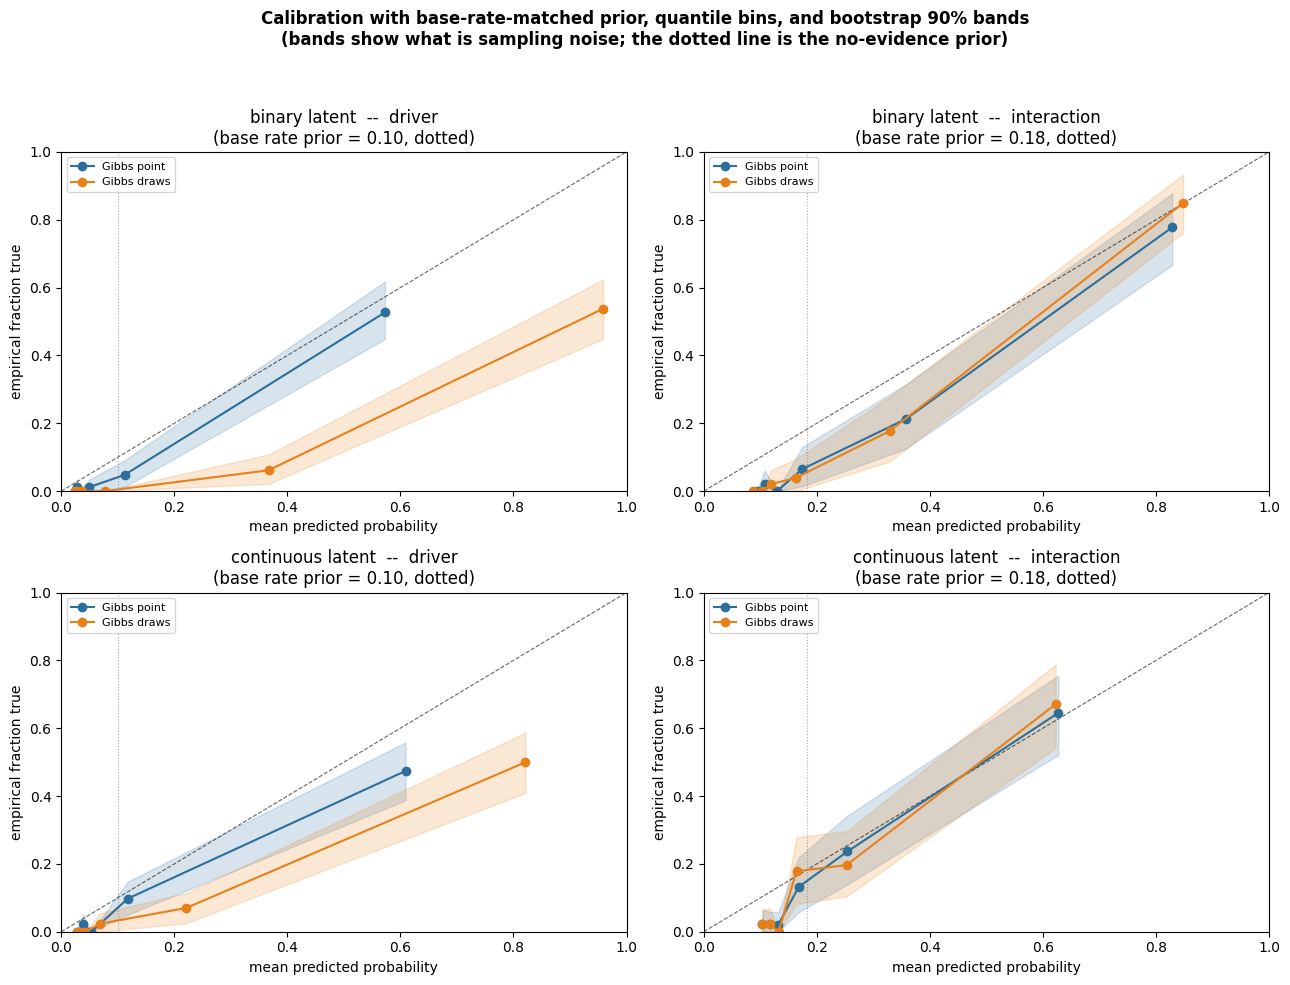

In [ ]:
"""
Gibbs point-estimate vs draws: calibration, done so noise and bias are separable
================================================================================
Fixes over the first pass:
  (1) PRIOR = the candidate set's ACTUAL base rate (not hard-coded). The earlier
      interaction prior (0.05) was far below the true rate (~0.18), which pushes
      every reliability point ABOVE the diagonal -- a systematic offset, not noise.
  (2) QUANTILE (equal-count) bins + a BOOTSTRAP BAND, so jaggedness that is just
      sampling noise is visibly inside the band; coarser bins are NOT used to hide
      it.
  (3) ECE / Brier reported with bootstrap 90% intervals, so we don't read tea
      leaves off a few points.
Self-contained.
"""

import numpy as np
from scipy.special import expit
import matplotlib.pyplot as plt

rng_boot = np.random.default_rng(0)

# ---------------- inference primitives ----------------
def logmeanexp(a):
    a = np.asarray(a, float); m = a.max(); return m + np.log(np.mean(np.exp(a - m)))

def logistic_logevidence(X, y, tau=4.0, iters=30):
    d = X.shape[1]; b = np.zeros(d); P = np.eye(d)/tau**2
    for _ in range(iters):
        mu = expit(X@b); W = mu*(1-mu)+1e-9; H = X.T@(X*W[:, None])+P
        step = np.linalg.solve(H, X.T@(y-mu)-P@b); b += step
        if np.max(np.abs(step)) < 1e-7: break
    eta = X@b; mu = expit(eta); W = mu*(1-mu)+1e-9
    ll = np.sum(y*eta-np.logaddexp(0., eta)); _, ld = np.linalg.slogdet(X.T@(X*W[:, None])+P)
    return ll-0.5*(b@b)/tau**2- 0.5*d*np.log(tau**2)-0.5*ld

def infer_Z_binary(G, n_draws=20, iters=250, burn=90, seed=0):
    rng = np.random.default_rng(seed); n, m = G.shape; Z = (rng.random(n) < .5).astype(int)
    dr = []; thin = max((iters-burn)//n_draws, 1)
    for it in range(iters):
        th = np.empty((m, 2))
        for z in (0, 1):
            on = G[Z == z].sum(0); th[:, z] = rng.beta(1+on, 1+((Z == z).sum()-on))
        pi = rng.beta(1+Z.sum(), 1+(n-Z.sum()))
        if th[:, 1].sum() < th[:, 0].sum(): th, pi, Z = th[:, ::-1], 1-pi, 1-Z
        lo = np.log(pi/(1-pi))+G@np.log(th[:, 1]/th[:, 0])+(1-G)@np.log((1-th[:, 1])/(1-th[:, 0]))
        Z = (rng.random(n) < expit(lo)).astype(int)
        if it >= burn and (it-burn) % thin == 0 and len(dr) < n_draws: dr.append(Z.astype(float))
    return np.array(dr)

def infer_Z_continuous(G, n_draws=20, iters=250, burn=90, seed=0):
    rng = np.random.default_rng(seed); n, m = G.shape
    Gs = (G-G.mean(0))/(G.std(0)+1e-9); lam = np.ones(m); psi = np.ones(m); Z = rng.standard_normal(n)
    dr = []; thin = max((iters-burn)//n_draws, 1)
    for it in range(iters):
        v = 1.0/(1.0+np.sum(lam**2/psi)); mu = v*(Gs@(lam/psi)); Z = mu+np.sqrt(v)*rng.standard_normal(n)
        zz = Z@Z+1e-6
        for j in range(m):
            lam[j] = (Gs[:, j]@Z)/zz + np.sqrt(psi[j]/zz)*rng.standard_normal()
        resid = Gs-np.outer(Z, lam); psi = (np.sum(resid**2, 0)+1.0)/rng.chisquare(n+2, size=m)
        if lam.sum() < 0: lam, Z = -lam, -Z
        if it >= burn and (it-burn) % thin == 0 and len(dr) < n_draws: dr.append(Z.copy())
    return np.array(dr)

def _design(one, Z, extra):
    cols = [one]
    if Z is not None:
        for k in range(Z.shape[1]): cols.append(Z[:, k])
    return np.column_stack(cols+extra)

def driver_logBF(Gg, T, cond_list):
    one = np.ones(len(T)); e0, e1 = [], []
    for Z in cond_list:
        e0.append(logistic_logevidence(_design(one, Z, []), T))
        e1.append(logistic_logevidence(_design(one, Z, [Gg]), T))
    return logmeanexp(e1)-logmeanexp(e0)

def interaction_logBF(Ga, Gb, T, cond_list):
    one = np.ones(len(T)); inter = Ga*Gb; ea, ei = [], []
    for Z in cond_list:
        ea.append(logistic_logevidence(_design(one, Z, [Ga, Gb]), T))
        ei.append(logistic_logevidence(_design(one, Z, [Ga, Gb, inter]), T))
    return logmeanexp(ei)-logmeanexp(ea)

def logbf_to_prob(logBF, prior):
    po = (prior/(1-prior))*np.exp(np.clip(logBF, -30, 30)); return po/(1+po)

# ---------------- data (same structure as the user's make_calibration_data) ----------------
def make_data(confound=0.55, n=700, n_pathways=2, per=5, n_null=20,
              latent="binary", gamma=None, driver_effect=1.0, inter_effect=1.2, seed=0):
    rng = np.random.default_rng(seed)
    if gamma is None: gamma = 1.7 if latent == "binary" else 1.25
    blocks, Zs = [], []
    for _ in range(n_pathways):
        if latent == "binary":
            Z = (rng.random(n) < .45).astype(float); th1, th0 = .5+confound/2, .5-confound/2
            B = (rng.random((n, per)) < np.where(Z[:, None] == 1, th1, th0)).astype(float)
        else:
            Z = rng.standard_normal(n); lam = .5+confound
            B = lam*Z[:, None]+np.sqrt(.3)*rng.standard_normal((n, per))
        Zs.append(Z); blocks.append(B)
    NU = (rng.random((n, n_null)) < .25).astype(float)
    Vraw = np.hstack(blocks+[NU])
    Vbin = (Vraw > np.median(Vraw, 0)).astype(float) if latent == "continuous" else Vraw.copy()
    true_drivers = [k*per+0 for k in range(n_pathways)]
    true_pairs = [(k*per+1, k*per+2) for k in range(n_pathways)]
    cand_drivers = list(range(n_pathways*per))+list(range(n_pathways*per, n_pathways*per+min(10, n_null)))
    null_drivers = [g for g in cand_drivers if g not in true_drivers]
    cand_pairs = []
    for k in range(n_pathways):
        b0 = k*per; cand_pairs += [(b0+1, b0+2), (b0+3, b0+4), (b0+0, b0+4)]
    n0 = n_pathways*per; cand_pairs += [(n0+q, n0+q+1) for q in range(0, min(10, n_null-1), 2)]
    null_pairs = [p for p in cand_pairs if p not in true_pairs]
    logit = -2.2
    for Z in Zs: logit = logit+gamma*Z
    for g in true_drivers: logit = logit+driver_effect*Vbin[:, g]
    for i, j in true_pairs: logit = logit+inter_effect*(Vbin[:, i]*Vbin[:, j])
    T = (rng.random(n) < expit(logit)).astype(int)
    return dict(Vbin=Vbin, Vraw=Vraw, T=T, Zt=np.column_stack(Zs), per=per, K=n_pathways,
                latent=latent, true_drivers=true_drivers, null_drivers=null_drivers,
                true_pairs=true_pairs, null_pairs=null_pairs)

def score_dataset(dat, n_draws=20, seed=0):
    rng = np.random.default_rng(seed); per, K = dat["per"], dat["K"]
    infer = infer_Z_binary if dat["latent"] == "binary" else infer_Z_continuous
    src = dat["Vbin"] if dat["latent"] == "binary" else dat["Vraw"]
    perpath = [infer(src[:, k*per:(k+1)*per], n_draws=n_draws, seed=int(rng.integers(1 << 31))) for k in range(K)]
    S = min(len(x) for x in perpath)
    Zdraws = [np.column_stack([perpath[k][s] for k in range(K)]) for s in range(S)]
    Zbar = [np.mean(Zdraws, axis=0)]
    arms = {"point": Zbar, "draws": Zdraws}
    # PRIORS = actual base rates of THIS candidate set
    pdrv = len(dat["true_drivers"])/(len(dat["true_drivers"])+len(dat["null_drivers"]))
    pint = len(dat["true_pairs"])/(len(dat["true_pairs"])+len(dat["null_pairs"]))
    Vbin, T = dat["Vbin"], dat["T"]; rows = []
    for arm, cond in arms.items():
        for g in dat["true_drivers"]+dat["null_drivers"]:
            lbf = driver_logBF(Vbin[:, g], T, cond)
            rows.append(("driver", arm, int(g in dat["true_drivers"]), logbf_to_prob(lbf, pdrv)))
        for (i, j) in dat["true_pairs"]+dat["null_pairs"]:
            lbf = interaction_logBF(Vbin[:, i], Vbin[:, j], T, cond)
            rows.append(("interaction", arm, int((i, j) in dat["true_pairs"]), logbf_to_prob(lbf, pint)))
    return rows, pdrv, pint

def run(latent, R=25, n_draws=20, seed0=1):
    rng = np.random.default_rng(seed0); allr = []; pd_ = pi_ = None
    for r in range(R):
        dat = make_data(latent=latent, seed=int(rng.integers(1 << 31)))
        rows, pd_, pi_ = score_dataset(dat, n_draws=n_draws, seed=int(rng.integers(1 << 31)))
        allr += rows
        if (r+1) % 5 == 0: print(f"  [{latent}] {r+1}/{R}")
    return allr, pd_, pi_

# ---------------- calibration with quantile bins + bootstrap band ----------------
def reliability_band(prob, truth, n_bins=6, B=400):
    edges = np.quantile(prob, np.linspace(0, 1, n_bins+1)); edges[0] -= 1e-9; edges[-1] += 1e-9
    bid = np.clip(np.digitize(prob, edges)-1, 0, n_bins-1)
    xs = np.array([prob[bid == b].mean() if (bid == b).any() else np.nan for b in range(n_bins)])
    n = len(prob); fr = np.full((B, n_bins), np.nan)
    for j in range(B):
        s = rng_boot.integers(0, n, n); bb = bid[s]; ts = np.asarray(truth)[s]
        for b in range(n_bins):
            m = bb == b
            if m.any(): fr[j, b] = ts[m].mean()
    return xs, np.nanmean(fr, 0), np.nanpercentile(fr, 5, 0), np.nanpercentile(fr, 95, 0)

def metrics_ci(prob, truth, n_bins=6, B=400):
    prob = np.asarray(prob, float); truth = np.asarray(truth, float)
    def one(p, y):
        brier = np.mean((p-y)**2)
        edges = np.quantile(p, np.linspace(0, 1, n_bins+1)); edges[0] -= 1e-9; edges[-1] += 1e-9
        bid = np.clip(np.digitize(p, edges)-1, 0, n_bins-1); ece = 0.
        for b in range(n_bins):
            m = bid == b
            if m.any(): ece += m.mean()*abs(y[m].mean()-p[m].mean())
        return brier, ece
    n = len(prob); bs, es = [], []
    for _ in range(B):
        s = rng_boot.integers(0, n, n); b, e = one(prob[s], truth[s]); bs.append(b); es.append(e)
    b0, e0 = one(prob, truth)
    return (b0, np.percentile(bs, [5, 95])), (e0, np.percentile(es, [5, 95]))

# ---------------- run both ----------------
R = 25
res = {}
for latent in ["binary", "continuous"]:
    rows, pdrv, pint = run(latent, R=R)
    res[latent] = (rows, pdrv, pint)

# ---------------- figure: 2 rows (latent) x 2 cols (driver/interaction) ----------------
armcol = {"point": "#2c6e9c", "draws": "#e8801a"}
fig, AX = plt.subplots(2, 2, figsize=(13, 10))
for row, latent in enumerate(["binary", "continuous"]):
    rows, pdrv, pint = res[latent]
    tgt_arr = np.array([r[0] for r in rows]); arm_arr = np.array([r[1] for r in rows])
    truth_arr = np.array([r[2] for r in rows]); prob_arr = np.array([r[3] for r in rows])
    for col, target in enumerate(["driver", "interaction"]):
        ax = AX[row, col]; ax.plot([0, 1], [0, 1], "k--", lw=.8, alpha=.6)
        base = pdrv if target == "driver" else pint
        ax.axvline(base, color="grey", lw=.8, ls=":", alpha=.7)
        for arm in ["point", "draws"]:
            m = (tgt_arr == target) & (arm_arr == arm)
            xs, mid, lo, hi = reliability_band(prob_arr[m], truth_arr[m])
            ax.fill_between(xs, lo, hi, color=armcol[arm], alpha=.18)
            ax.plot(xs, mid, "o-", color=armcol[arm], label=f"Gibbs {arm}")
        ax.set_title(f"{latent} latent  --  {target}\n(base rate prior = {base:.2f}, dotted)")
        ax.set_xlabel("mean predicted probability"); ax.set_ylabel("empirical fraction true")
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(fontsize=8, loc="upper left")
fig.suptitle("Calibration with base-rate-matched prior, quantile bins, and bootstrap 90% bands\n"
             "(bands show what is sampling noise; the dotted line is the no-evidence prior)",
             fontsize=12, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig("calibration_fixed.png", dpi=135)

print("\n================ METRICS (point estimate, 90% CI) ================")
for latent in ["binary", "continuous"]:
    rows, pdrv, pint = res[latent]
    tgt = np.array([r[0] for r in rows]); arm = np.array([r[1] for r in rows])
    tr = np.array([r[2] for r in rows]); pr = np.array([r[3] for r in rows])
    print(f"\n--- {latent} latent ---")
    for target in ["driver", "interaction"]:
        for a in ["point", "draws"]:
            m = (tgt == target) & (arm == a)
            (b, bci), (e, eci) = metrics_ci(pr[m], tr[m])
            print(f"  {target:11s} {a:6s}  Brier={b:.3f} [{bci[0]:.3f},{bci[1]:.3f}]   "
                  f"ECE={e:.3f} [{eci[0]:.3f},{eci[1]:.3f}]")
print("\nsaved -> calibration_fixed.png")

  10/40 cohorts
  20/40 cohorts
  30/40 cohorts
  40/40 cohorts

================ SUMMARY ================
INTERACTIONS  AUC: beta(=Platt-beta) 0.67 | naive 0.93 | pathway 0.95
   ECE: Platt-beta 0.034 | pathway-P 0.098
DRIVERS       AUC: alpha(=Platt-alpha) 0.89 | GWAS 0.78 | pathway 0.99
   ECE: Platt-alpha 0.066 | pathway-P 0.048
saved -> calibrating_alpha_beta.png


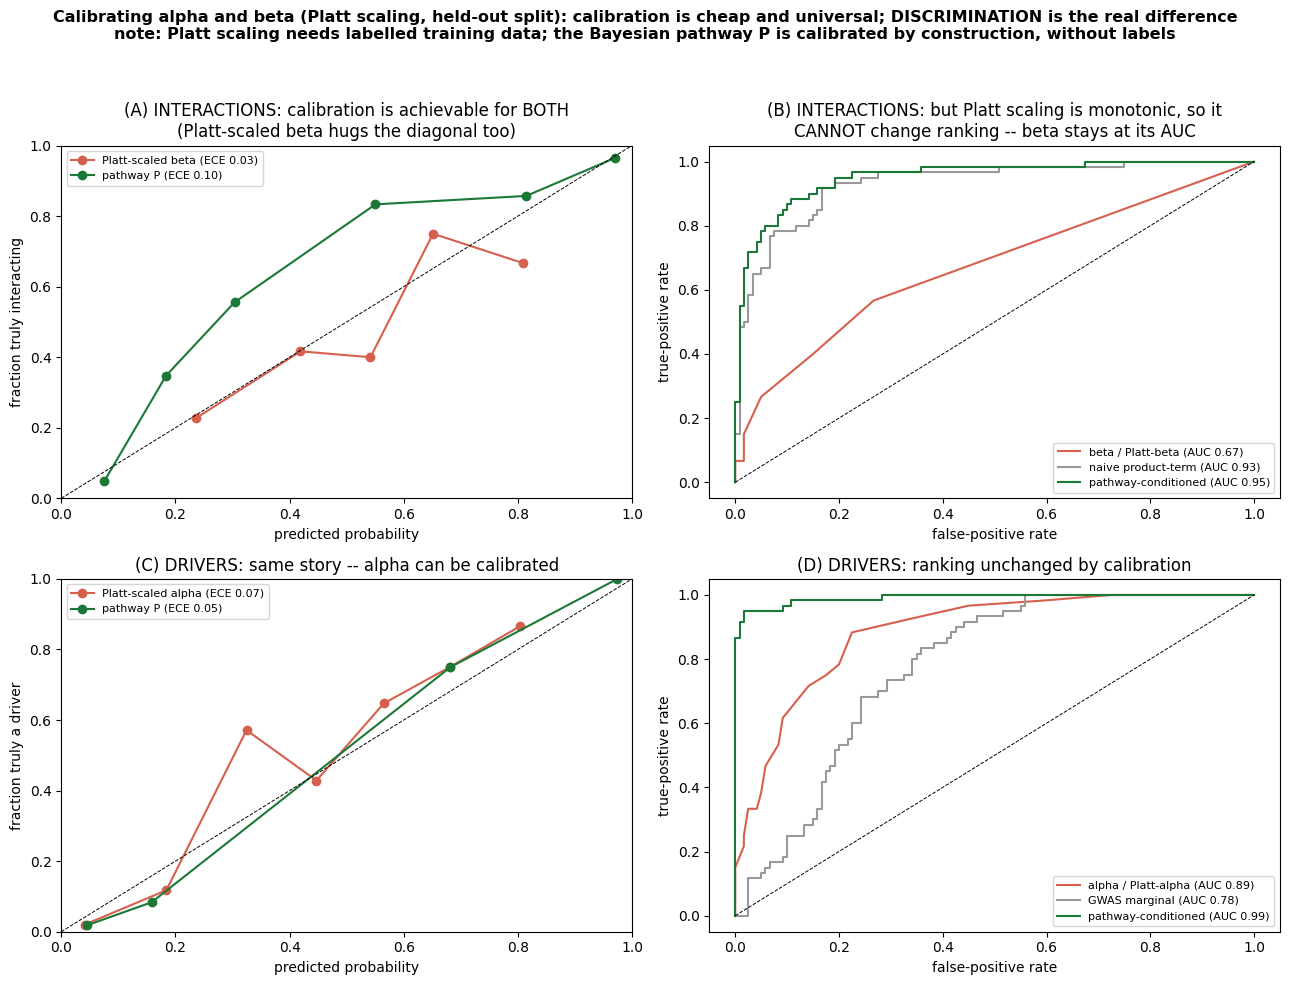

In [2]:
"""
Can we calibrate IBI-DT's alpha and beta?  Platt scaling, done honestly
=======================================================================
Claim under test: alpha (drivers) and beta (interactions) are scores, not
probabilities, but a Platt-scaling layer  P(true | s) = sigmoid(d0 + d1*s)
turns any score into a calibrated probability -- so is the pathway method's
advantage just that it outputs probabilities?

Answer this script demonstrates:
  * CALIBRATION is cheap and universal. Platt-scaled beta (and alpha) hug the
    reliability diagonal, just like the Bayesian probabilities. Outputting a
    calibrated probability is NOT the differentiator.
  * DISCRIMINATION is the differentiator, and Platt scaling cannot touch it.
    Platt scaling is monotonic, so AUC(Platt-beta) == AUC(raw beta). beta stays
    at AUC ~0.6 while the pathway-conditioned test is ~0.9. A calibrated bad
    score is still a bad score -- it is just no longer overconfident about it.
  * Two honest caveats, flagged on the figure:
      (1) Platt scaling must be fit on a HELD-OUT labelled split (done here:
          calibration cohorts vs test cohorts are disjoint), else it is circular.
      (2) Platt scaling NEEDS labelled training data; the Bayesian P is
          calibrated BY CONSTRUCTION from the model, with no labels.

Self-contained: numpy / scipy / sklearn / matplotlib.
"""

import numpy as np
from scipy.special import gammaln, expit, logsumexp
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt

# ---------------- IBI-DT marginal likelihood, tree, ensemble ----------------
def lgm_edge(T, V):
    T = T.astype(np.int64); V = V.astype(np.int64); t1, t0 = T, 1-T
    a1, a0 = t1@V, t0@V; b1, b0 = t1@(1-V), t0@(1-V); lg = np.zeros(V.shape[1])
    for a, b in [(b0, b1), (a0, a1)]:
        lg += gammaln(2.)-gammaln(2.+a+b)+gammaln(1.+a)+gammaln(1.+b)
    return lg
def lgm_noparent(T):
    N = len(T); N1 = int(T.sum())
    return gammaln(2.)-gammaln(2.+N)+gammaln(1.+N-N1)+gammaln(1.+N1)
def grow(T, V, idx, cand, d, md, nq, mn, used, path, paths):
    Tn = T[idx]
    if d >= md or len(idx) < mn or Tn.min() == Tn.max(): paths.append(list(path)); return
    us = [c for c in cand if c not in used and V[idx, c].min() != V[idx, c].max()]
    if not us: paths.append(list(path)); return
    g = lgm_edge(Tn, V[np.ix_(idx, us)]) - lgm_noparent(Tn); j = int(np.argmax(g))
    if g[j] <= nq: paths.append(list(path)); return
    s = us[j]
    for br in (0, 1):
        ch = idx[V[idx, s] == br]
        if len(ch): grow(T, V, ch, cand, d+1, md, nq, mn, used | {s}, path+[(s, br)], paths)
def ibidt(T, V, N=25, md=4, q=0.1, mn=25, rng=None):
    rng = rng or np.random.default_rng(0); p = V.shape[1]; cand = list(range(p)); nq = -np.log(q)
    alpha = np.zeros(p); beta = {}; i1, i0 = np.where(T == 1)[0], np.where(T == 0)[0]; an = bn = 0
    for _ in range(N):
        bs = np.concatenate([rng.choice(i0, len(i0), True), rng.choice(i1, len(i1), True)])
        paths = []; grow(T[bs], V[bs], np.arange(len(bs)), cand, 0, md, nq, mn, set(), [], paths)
        for s in {v for pth in paths for v, _ in pth}: alpha[s] += 1
        seen = set()
        for pth in paths:
            vs = [v for v, _ in pth]
            for x in range(len(vs)):
                for y in range(x+1, len(vs)):
                    k = (min(vs[x], vs[y]), max(vs[x], vs[y]))
                    if k not in seen: beta[k] = beta.get(k, 0)+1; seen.add(k)
        ac, bc, s2 = {}, {}, set()
        for pth in paths:
            rl = [int(rng.integers(p)) for _ in pth]
            for v in set(rl): ac[v] = ac.get(v, 0)+1
            for x in range(len(rl)):
                for y in range(x+1, len(rl)):
                    k = (min(rl[x], rl[y]), max(rl[x], rl[y]))
                    if k not in s2: bc[k] = bc.get(k, 0)+1; s2.add(k)
        an = max(an, max(ac.values()) if ac else 0); bn = max(bn, max(bc.values()) if bc else 0)
    return alpha, beta, an, bn

# ---------------- pathway inference + conditioned tests ----------------
def logev(X, y, tau=4., iters=40):
    d = X.shape[1]; b = np.zeros(d); P = np.eye(d)/tau**2
    for _ in range(iters):
        mu = expit(X@b); W = mu*(1-mu)+1e-9; H = X.T@(X*W[:, None])+P
        st = np.linalg.solve(H, X.T@(y-mu)-P@b); b += st
        if np.max(np.abs(st)) < 1e-7: break
    eta = X@b; mu = expit(eta); W = mu*(1-mu)+1e-9
    ll = np.sum(y*eta-np.logaddexp(0., eta)); _, ld = np.linalg.slogdet(X.T@(X*W[:, None])+P)
    return ll-0.5*(b@b)/tau**2- 0.5*d*np.log(tau**2)-0.5*ld
def wald_p(X, y, idx, iters=40):
    from math import erfc, sqrt
    d = X.shape[1]; b = np.zeros(d)
    for _ in range(iters):
        mu = expit(X@b); W = mu*(1-mu)+1e-9; H = X.T@(X*W[:, None])+1e-6*np.eye(d)
        st = np.linalg.solve(H, X.T@(y-mu)); b += st
        if np.max(np.abs(st)) < 1e-7: break
    mu = expit(X@b); W = mu*(1-mu)+1e-9; cov = np.linalg.inv(X.T@(X*W[:, None])+1e-9*np.eye(d))
    z = b[idx]/np.sqrt(max(cov[idx, idx], 1e-12)); return erfc(abs(z)/sqrt(2))
def infer_Z(G, n_draws=6, iters=250, burn=90, seed=0):
    rng = np.random.default_rng(seed); n, m = G.shape; Z = (rng.random(n) < .5).astype(int)
    dr = []; thin = max((iters-burn)//n_draws, 1)
    for it in range(iters):
        th = np.empty((m, 2))
        for z in (0, 1):
            on = G[Z == z].sum(0); th[:, z] = rng.beta(1+on, 1+((Z == z).sum()-on))
        pi = rng.beta(1+Z.sum(), 1+(n-Z.sum()))
        if th[:, 1].sum() < th[:, 0].sum(): th, pi, Z = th[:, ::-1], 1-pi, 1-Z
        lo = np.log(pi/(1-pi))+G@np.log(th[:, 1]/th[:, 0])+(1-G)@np.log((1-th[:, 1])/(1-th[:, 0]))
        Z = (rng.random(n) < expit(lo)).astype(int)
        if it >= burn and (it-burn) % thin == 0 and len(dr) < n_draws: dr.append(Z.astype(float))
    return np.array(dr)
def drv_logBF(Gg, T, Zl):
    one = np.ones(len(T)); e0, e1 = [], []
    for Z in Zl:
        base = np.column_stack([one]+[Z[:, k] for k in range(Z.shape[1])])
        e0.append(logev(base, T)); e1.append(logev(np.column_stack([base, Gg]), T))
    return (logsumexp(e1)-np.log(len(e1)))-(logsumexp(e0)-np.log(len(e0)))
def int_logBF(Ga, Gb, T, Zl):
    one = np.ones(len(T)); inter = Ga*Gb; ea, ei = [], []
    for Z in Zl:
        base = np.column_stack([one]+[Z[:, k] for k in range(Z.shape[1])]+[Ga, Gb])
        ea.append(logev(base, T)); ei.append(logev(np.column_stack([base, inter]), T))
    return (logsumexp(ei)-np.log(len(ei)))-(logsumexp(ea)-np.log(len(ea)))

# ---------------- one cohort ----------------
PER = 6; NPATH = 2
def cohort(seed, n=600, confound=0.6):
    rng = np.random.default_rng(seed); th1, th0 = .5+confound/2, .5-confound/2
    Zs, blocks = [], []
    for _ in range(NPATH):
        Z = (rng.random(n) < .45).astype(float); Zs.append(Z)
        B = np.array([(rng.random(n) < np.where(Z == 1, th1, th0)).astype(float) for _ in range(PER)]).T
        blocks.append(B)
    M = np.hstack(blocks)                                   # 12 marker cols
    dr_eff = rng.uniform(.9, 2.0, 3); D = (rng.random((n, 3)) < .30).astype(float)   # 3 true drivers
    gam = rng.uniform(1.0, 2.6, 3); E = (rng.random((n, 6)) < .5).astype(float)      # 3 true pairs
    NU = (rng.random((n, 12)) < .30).astype(float)          # null genes
    V = np.hstack([M, D, E, NU]); oM, oD, oE, oN = 0, 12, 15, 21
    logit = -2.0
    for Z in Zs: logit = logit+2.2*Z
    for k in range(3): logit = logit+dr_eff[k]*D[:, k]
    for k in range(3): logit = logit+gam[k]*((E[:, 2*k] > .5) & (E[:, 2*k+1] > .5)).astype(float)
    T = (rng.random(n) < expit(logit)).astype(int)
    alpha, beta, an, bn = ibidt(T, V, rng=rng)
    Zd = [infer_Z(M[:, p*PER:(p+1)*PER], seed=seed+1+p) for p in range(NPATH)]
    S = min(len(z) for z in Zd); Zl = [np.column_stack([Zd[p][s] for p in range(NPATH)]) for s in range(S)]
    one = np.ones(n)
    # variant records: (label, alpha, gwas, pathBF)
    var = []
    for c, lab in ([(oD+k, 1) for k in range(3)] + [(oM+k, 0) for k in range(3)] + [(oN+k, 0) for k in range(3)]):
        Gg = V[:, c]
        gw = -np.log(max(wald_p(np.column_stack([one, Gg]), T, 1), 1e-300))
        var.append((lab, alpha[c], gw, drv_logBF(Gg, T, Zl)))
    # pair records: (label, beta, gwas, pathBF)
    pair = []
    pl = ([((oE+2*k, oE+2*k+1), 1) for k in range(3)]
          + [((oM+0, oM+1), 0), ((oM+2, oM+3), 0), ((oM+6, oM+7), 0)]
          + [((oN+0, oN+1), 0), ((oN+2, oN+3), 0), ((oN+4, oN+5), 0)])
    for (a, b), lab in pl:
        Ga, Gb = V[:, a], V[:, b]
        gw = -np.log(max(wald_p(np.column_stack([one, Ga, Gb, Ga*Gb]), T, 3), 1e-300))
        pair.append((lab, beta.get((min(a, b), max(a, b)), 0), gw, int_logBF(Ga, Gb, T, Zl)))
    return var, pair

R = 40
allv, allp = [], []
for r in range(R):
    v, p = cohort(seed=1000*r); allv += [(r,)+x for x in v]; allp += [(r,)+x for x in p]
    if (r+1) % 10 == 0: print(f"  {r+1}/{R} cohorts")
allv = np.array(allv, float); allp = np.array(allp, float)   # cols: cohort,label,score_ibidt,gwas,pathBF

# split cohorts -> calibration vs test (disjoint)
calib_cohorts = set(range(0, R, 2)); 
def split(arr):
    cal = np.array([row[0] in calib_cohorts for row in arr]); return arr[cal], arr[~cal]
v_cal, v_test = split(allv); p_cal, p_test = split(allp)

def base_rate(arr): return arr[:, 1].mean()
def to_prob(lbf, pi0): bf = np.exp(np.clip(lbf, -30, 30)); return pi0*bf/(pi0*bf+(1-pi0))
def platt(score_cal, lab_cal, score_test):
    s = np.log1p(np.clip(score_cal, 0, None)).reshape(-1, 1)
    lr = LogisticRegression().fit(s, lab_cal)
    return lr.predict_proba(np.log1p(np.clip(score_test, 0, None)).reshape(-1, 1))[:, 1]
def ece(pred, y, nb=10):
    ed = np.linspace(0, 1, nb+1); e = 0.
    for i in range(nb):
        m = (pred >= ed[i]) & ((pred <= ed[i+1]) if i == nb-1 else (pred < ed[i+1]))
        if m.sum(): e += m.sum()/len(pred)*abs(y[m].mean()-pred[m].mean())
    return e
def reliability(pred, y, nb=8):
    ed = np.linspace(0, 1, nb+1); cf, ac = [], []
    for i in range(nb):
        m = (pred >= ed[i]) & ((pred <= ed[i+1]) if i == nb-1 else (pred < ed[i+1]))
        if m.sum() >= 4: cf.append(pred[m].mean()); ac.append(y[m].mean())
    return cf, ac

# ---- interactions: Platt-scale beta; pathway P by construction ----
pi0_p = base_rate(allp)
beta_platt = platt(p_cal[:, 2], p_cal[:, 1], p_test[:, 2])
path_P_p = to_prob(p_test[:, 4], pi0_p)
gwas_P_p = to_prob(p_test[:, 3] - np.log(20), pi0_p)   # rough: -log p centred near p=0.05
lab_p = p_test[:, 1]
auc_beta = roc_auc_score(lab_p, p_test[:, 2]); auc_naive = roc_auc_score(lab_p, p_test[:, 3])
auc_path = roc_auc_score(lab_p, p_test[:, 4])

# ---- drivers: Platt-scale alpha; pathway P by construction ----
pi0_v = base_rate(allv)
alpha_platt = platt(v_cal[:, 2], v_cal[:, 1], v_test[:, 2])
path_P_v = to_prob(v_test[:, 4], pi0_v)
lab_v = v_test[:, 1]
auc_alpha = roc_auc_score(lab_v, v_test[:, 2]); auc_gwasv = roc_auc_score(lab_v, v_test[:, 3])
auc_pathv = roc_auc_score(lab_v, v_test[:, 4])

# ---------------- figure ----------------
fig, ax = plt.subplots(2, 2, figsize=(13, 10))

# (A) interactions reliability: Platt-beta vs pathway-P
for pred, color, name in [(beta_platt, "#d6604d", f"Platt-scaled beta (ECE {ece(beta_platt, lab_p):.2f})"),
                          (path_P_p, "#1b7837", f"pathway P (ECE {ece(path_P_p, lab_p):.2f})")]:
    cf, acc = reliability(pred, lab_p); ax[0, 0].plot(cf, acc, "o-", color=color, label=name)
ax[0, 0].plot([0, 1], [0, 1], "k--", lw=.7)
ax[0, 0].set_title("(A) INTERACTIONS: calibration is achievable for BOTH\n(Platt-scaled beta hugs the diagonal too)")
ax[0, 0].set_xlabel("predicted probability"); ax[0, 0].set_ylabel("fraction truly interacting")
ax[0, 0].set_xlim(0, 1); ax[0, 0].set_ylim(0, 1); ax[0, 0].legend(fontsize=8)

# (B) interactions ROC: beta (=Platt-beta) vs naive vs pathway
for sc, color, name in [(p_test[:, 2], "#d6604d", f"beta / Platt-beta (AUC {auc_beta:.2f})"),
                        (p_test[:, 3], "#999999", f"naive product-term (AUC {auc_naive:.2f})"),
                        (p_test[:, 4], "#1b7837", f"pathway-conditioned (AUC {auc_path:.2f})")]:
    fpr, tpr, _ = roc_curve(lab_p, sc); ax[0, 1].plot(fpr, tpr, color=color, label=name)
ax[0, 1].plot([0, 1], [0, 1], "k--", lw=.7)
ax[0, 1].set_title("(B) INTERACTIONS: but Platt scaling is monotonic, so it\nCANNOT change ranking -- beta stays at its AUC")
ax[0, 1].set_xlabel("false-positive rate"); ax[0, 1].set_ylabel("true-positive rate"); ax[0, 1].legend(fontsize=8, loc="lower right")

# (C) drivers reliability
for pred, color, name in [(alpha_platt, "#d6604d", f"Platt-scaled alpha (ECE {ece(alpha_platt, lab_v):.2f})"),
                          (path_P_v, "#1b7837", f"pathway P (ECE {ece(path_P_v, lab_v):.2f})")]:
    cf, acc = reliability(pred, lab_v); ax[1, 0].plot(cf, acc, "o-", color=color, label=name)
ax[1, 0].plot([0, 1], [0, 1], "k--", lw=.7)
ax[1, 0].set_title("(C) DRIVERS: same story -- alpha can be calibrated")
ax[1, 0].set_xlabel("predicted probability"); ax[1, 0].set_ylabel("fraction truly a driver")
ax[1, 0].set_xlim(0, 1); ax[1, 0].set_ylim(0, 1); ax[1, 0].legend(fontsize=8)

# (D) drivers ROC
for sc, color, name in [(v_test[:, 2], "#d6604d", f"alpha / Platt-alpha (AUC {auc_alpha:.2f})"),
                        (v_test[:, 3], "#999999", f"GWAS marginal (AUC {auc_gwasv:.2f})"),
                        (v_test[:, 4], "#1b7837", f"pathway-conditioned (AUC {auc_pathv:.2f})")]:
    fpr, tpr, _ = roc_curve(lab_v, sc); ax[1, 1].plot(fpr, tpr, color=color, label=name)
ax[1, 1].plot([0, 1], [0, 1], "k--", lw=.7)
ax[1, 1].set_title("(D) DRIVERS: ranking unchanged by calibration")
ax[1, 1].set_xlabel("false-positive rate"); ax[1, 1].set_ylabel("true-positive rate"); ax[1, 1].legend(fontsize=8, loc="lower right")

fig.suptitle("Calibrating alpha and beta (Platt scaling, held-out split): calibration is cheap and universal; "
             "DISCRIMINATION is the real difference\n"
             "note: Platt scaling needs labelled training data; the Bayesian pathway P is calibrated by construction, without labels",
             fontsize=11.5, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig("calibrating_alpha_beta.png", dpi=135)

print("\n================ SUMMARY ================")
print(f"INTERACTIONS  AUC: beta(=Platt-beta) {auc_beta:.2f} | naive {auc_naive:.2f} | pathway {auc_path:.2f}")
print(f"   ECE: Platt-beta {ece(beta_platt, lab_p):.3f} | pathway-P {ece(path_P_p, lab_p):.3f}")
print(f"DRIVERS       AUC: alpha(=Platt-alpha) {auc_alpha:.2f} | GWAS {auc_gwasv:.2f} | pathway {auc_pathv:.2f}")
print(f"   ECE: Platt-alpha {ece(alpha_platt, lab_v):.3f} | pathway-P {ece(path_P_v, lab_v):.3f}")
print("saved -> calibrating_alpha_beta.png")